<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_RobQuNNs_Maouaki2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RobQuNNs: robust quanvolutional neural networks against adversarial attacks (Maouaki et al., 2024) step by step

This notebook re-implements, runs and stress-tests the experiments of

> Walid El Maouaki, Alberto Marchisio, Taoufik Said, Muhammad Shafique and Mohamed Bennai,
> "RobQuNNs: A Methodology for Robust Quanvolutional Neural Networks against Adversarial Attacks",
> *IEEE International Conference on Image Processing Challenges and Workshops (ICIPCW)* 2024, DOI [10.1109/ICIPCW64161.2024.10769105](https://doi.org/10.1109/icipcw64161.2024.10769105), arXiv:2407.03875v1.

**What the notebook does.** It builds the paper's *quanvolutional neural network* (QuNN): a fixed 4-qubit "quantum convolution" with a 2 x 2 kernel and stride 2 (one `RY` angle-encoding gate per pixel,
a parameterised **Ansatz**, Pauli-Z read-out of every qubit giving 4 output channels) followed by a trainable dense softmax layer. The paper's *RobQuNN methodology* says: **vary the entanglement
capability of the Ansatz** (no entanglement, ZZ full, ZZ linear, ZZ star, random) and the QuNN becomes more or less robust. The notebook trains the five QuNNs and the paper's classical CNN on MNIST,
attacks them in the white-box setting with **FGSM, PGD and MIM** over a range of perturbation strengths, re-draws the paper's Figure 3 (white-box curves and the two cross-model transfer experiments),
and checks claim by claim whether the paper's statements are reproduced.

**What it adds (the lesson of the sister paper QC-237, AdvQuNN).** In that earlier notebook a large part of the QuNN "robustness" turned out to be one-step FGSM *saturation* (a form of gradient masking).
Here the claims are therefore tested, not just displayed: (i) a **no-quantum control** (a frozen classical convolution with the same bounded, periodic output range as `<Z>`) and a trainable CNN are attacked identically,
(ii) an **adaptive multi-step attack** (random restarts, margin loss, success at any iterate) and a random-noise attack are added to the paper's three attacks, and (iii) a **worst-case envelope** over all attacks
and all smaller epsilons gives an upper bound on the true robust accuracy.

**How to run.** Open in Google Colab (badge above), choose a *CPU* runtime, and use *Runtime -> Run all*. `FAST_MODE = True` (2 trials, 50 attacked images per trial; this is the stored run) takes a few minutes on a quiet CPU and about 45 minutes on a heavily shared one; `FAST_MODE = False` (5 trials, 200 attacked images, longer attacks; budgets in the configuration cell)
needs several hours and was not executed for the stored notebook. All circuits are simulated exactly (4 qubits per patch); no quantum hardware, no IBM token and no Hugging Face token is needed (MNIST is not gated; the Hugging Face fallback uses `HF_TOKEN` from the environment or from Colab *Settings -> Secrets* only if the reader has set one).

**What you get at the end.** Class distributions and 2-D projections of the real images, drawings of the executed circuits (one per architecture, checked against the NumPy simulator that does the heavy lifting), accuracy-vs-epsilon curves
for every model and attack (Figure 3 a-c and the five architectures), the transfer matrices (Figure 3 d, e), the adaptive-attack stress test and a table of per-claim verdicts ("reproduced" / "not reached" / "exceeded" / "cannot be checked").

## The paper in one page

**Problem.** Hybrid quantum-classical networks such as the *quanvolutional* neural network (QuNN, Henderson et al. 2020) replace the convolution filter of a CNN by a small quantum circuit. Earlier work (AdvQuNN, QC-237) found that QuNNs resist
white-box attacks better than CNNs but did not isolate *why*. **RobQuNN** argues that the *expressibility and entanglement capability* of the circuit (the "Ansatz"), controlled through its gate set and entanglement pattern, determines the robustness,
and also asks how adversarial examples **transfer** between classical and quantum models.

**Model (Fig. 1, Fig. 2).** A 28 x 28 MNIST image is cut into 2 x 2 patches with stride 2. Each patch is **angle-encoded** with a rotation gate around the y axis (`Ry(x)`, Fig. 1) on 4 qubits, a **parameterised unitary U(theta)** is applied, and `<Z>`
of each qubit becomes one of 4 channels of a 14 x 14 feature map, which is flattened into a `Dense(10, softmax)` layer. The CNN twin is `Conv2D(4 filters, 2 x 2, stride 2, relu)` followed by the same dense layer. In **both** models the convolution is a *fixed feature
extractor* (non-trainable); only the dense layer is trained (Adam, sparse categorical cross-entropy, 30 epochs, batch size 4, learning rate 0.001).

**Five Ansatz architectures (Section 3.1).** All use `Rot(a,b,c) = Rz(a) Ry(b) Rz(c)` on every qubit, one layer. *No entanglement*: nothing else. *ZZ full*: `exp(-i phi Z Z)` between all 6 pairs. *ZZ linear*: nearest-neighbour pairs. *ZZ star*: qubit 1 with all others.
*Random*: random gate selection with a single entangling operation.

**Attacks (Section 3.2, 4.1).** White-box FGSM, PGD and MIM (Cleverhans) over a range of epsilon from low to high; accuracy-vs-epsilon plots (Fig. 3a-c). Black-box: FGSM examples crafted on the CNN and applied to each QuNN (Fig. 3d) and crafted on each QuNN
and applied to the CNN (Fig. 3e).

**Claims that can be checked here.**
1. QuNNs are more robust than the classical CNN under FGSM, PGD and MIM, "particularly at low levels of perturbation" and "up to **60 %** higher robustness for MNIST" (abstract, Section 4.2).
2. Among the Ansatzes **ZZ full is the most robust** and **random the least** (Section 4.2, 4.4); ZZ full and ZZ star behave alike at low epsilon.
3. Transfer CNN -> QuNN (Fig. 3d): all five Ansatzes decline similarly; transfer QuNN -> CNN (Fig. 3e): same, and the CNN is slightly more robust against QuNN-crafted examples than the QuNNs are against CNN-crafted ones (Section 4.3).
4. The adversarial examples keep their efficacy across the model boundary, independent of the entanglement pattern (Section 4.3-4.4).

### What follows the paper and what had to be chosen

The paper states the model, the optimiser and the attack families but publishes neither code nor the training-set size, the epsilon grid, the PGD/MIM hyper-parameters, the random-circuit definition or any table of numbers (results are plots only).
Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Quantum filter | 2 x 2 kernel, stride 2, 4 qubits, `Ry(x)` angle encoding (Fig. 1), `<Z>` on each qubit = 4 channels | same; PennyLane circuit (`AngleEmbedding`, `Rot`, `CNOT-RZ-CNOT`, `expval(PauliZ)`); the heavy lifting is done by an exact NumPy statevector simulator **asserted equal** to the PennyLane QNode |
| Encoding angle | `Ry(x)` with x the pixel value (Fig. 1); scale not discussed | angle = `ENC_SCALE * pixel`, `ENC_SCALE = 1.0` (`# CHOICE`, literal reading of Fig. 1). The sister paper QC-237 used `pi * pixel`; a short ablation with `pi` is run at the end |
| ZZ entanglers | `exp(-i phi Z Z)`, `phi` a free angle; text says `n + 1` operations for the linear chain (n - 1 pairs are meant) | `CNOT - RZ(phi) - CNOT`, one free angle per pair: 6 / 3 / 3 pairs for full / linear / star (centre = first qubit) |
| Quantum parameters | convolution non-trainable; initial values not stated | uniform in [0, 2 pi), one fresh draw per trial (`# CHOICE`) |
| Random architecture | "random gate selection ... only a single entanglement operation" | 4 rotations (`RX`/`RY`/`RZ`, random qubit) and **one** `CNOT` at a random position, a new circuit per trial (`# CHOICE`) |
| Classical CNN | `Conv2D(4, 2x2, stride 2, relu)` + `Dense(10, softmax)`, convolution non-trainable | frozen Keras-style Glorot-uniform kernel, zero bias (`# CHOICE` for the initialiser). A trainable CNN is added as an extra control |
| Training | 30 epochs, batch 4, Adam, lr 0.001; **number of images not stated** | `N_TRAIN` class-balanced random MNIST training images (300 in FAST_MODE, 500 in the full run, `# CHOICE`), a new draw per trial; no early stopping and no tuning, so no validation split is needed |
| Test set | not stated | `N_TEST` class-balanced test images (50 in FAST_MODE, 200 in the full run, `# CHOICE`), same images for all models of a trial |
| Trials / error bars | not stated | `N_TRIALS` independent trials (2 in FAST_MODE, 5 in the full run), mean +- std |
| FGSM / PGD / MIM | Cleverhans; PGD step, iterations and MIM decay not given | FGSM; Madry PGD with `k` steps of `2.5 eps / k` and no random start; MIM with `mu = 1`, per-image L1 normalisation (`# CHOICE`, `k = 10`, 5 in FAST_MODE) |
| Epsilon grid | "from low to high relative to each attack" | `0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10` for all attacks (`# CHOICE`); pixels clipped to [0, 1] |
| Gradients | TensorFlow autodiff through the quantum layer | exact analytic input gradient of the quanvolution layer, verified against finite differences below |
| Transfer (Fig. 3d, e) | FGSM examples between CNN and QuNNs | same, on the same images and epsilons |
| **No-quantum control** | not in the paper | frozen classical convolution with `cos(w.patch + b)` output (bounded, periodic like `<Z>`), plus a trainable CNN |
| **Adaptive attack** | not in the paper | margin-loss PGD, random restarts, success at any iterate, plus a random-noise attack and a worst-case envelope |
| Quantum hardware | none (simulation) | none |

In [1]:
# --- installs, pinned to the versions this notebook was tested with. PennyLane draws the circuits and cross-checks the NumPy simulator.
# --- Colab already ships numpy, pandas, scikit-learn, matplotlib, scipy and requests.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
if IN_COLAB or not _have("pennylane"):
    !pip -q install "pennylane==0.45.1"
    # a runtime restart is normally NOT needed; if an import below fails, restart once and Run all again

In [2]:
# ----------------------------------------------- configuration: every tunable constant lives here -----------------------------------------------
SEED = 42
FAST_MODE = True             # True: the stored run (2 trials, 300 train / 50 test images per trial, 5-step PGD/MIM, 1 x 10-step adaptive attack); False: the full budget (5 trials, 500 train / 200 test images, 10-step PGD/MIM, 2 x 20-step adaptive attack)
IBM_TOKEN = ""               # not used: every circuit is simulated exactly (4 qubits per patch); kept for symmetry with the other notebooks

DATA_DIR = "qc268_data"      # MNIST is cached here (or upload mnist.npz into this folder)

# training recipe from the paper (Section 4.1): 30 epochs, batch 4, Adam, lr 0.001, sparse categorical cross-entropy
BATCH_SIZE, EPOCHS, LR = 4, 30, 1e-3
# CHOICE (the paper does not state them): sizes and number of trials
N_TRAIN, N_TEST, N_TRIALS = (300, 50, 2) if FAST_MODE else (500, 200, 5)
ENC_SCALE = 1.0              # CHOICE: encoding gate Ry(ENC_SCALE * pixel); 1.0 = literal Fig. 1 of the paper, np.pi = the sister paper QC-237
RUN_PI_ABLATION = True       # extra: repeat the key comparison with ENC_SCALE = pi (2 trials in FAST_MODE, 3 in the full run)

# attacks (CHOICE: the paper only says "from low to high")
EPS = [0.0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
ATTACK_ITERS = 5 if FAST_MODE else 10      # CHOICE: k steps for PGD / MIM, step size alpha = 2.5 eps / k
MIM_MU = 1.0                               # CHOICE: momentum decay factor
# adaptive attack added by this notebook (not in the paper): margin loss + random restarts + success at any iterate, on the clean-correct images
AA_EPS = [0.01, 0.03, 0.1, 0.3, 1.0, 10.0]
AA_STEPS = 10 if FAST_MODE else 20
AA_RESTARTS = 1 if FAST_MODE else 2
RND_DRAWS = 3 if FAST_MODE else 5          # random-sign noise attack: worst case over this many draws

ARCHS = ["no_ent", "zz_full", "zz_linear", "zz_star", "random"]      # the five Ansatz architectures of Section 3.1
MODELS = ["CNN", "CNN_train", "PERIODIC"] + ARCHS                     # CNN = the paper's frozen CNN; CNN_train, PERIODIC = extra classical controls
# Full-run budget (FAST_MODE=False): 5 trials x 8 models x (FGSM + PGD + MIM + adaptive + noise) on 200 test images, 30 epochs on 500 images. It was NOT executed for the stored notebook: the FAST run alone takes
# about 45 minutes on a heavily shared CPU, the full budget needs roughly 10-20 times more (several hours) - run it in Colab or on a quiet machine for tighter error bars.

In [3]:
import os, time, math, warnings, io, gzip
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import requests, scipy, sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import pennylane as qml
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="Mean of empty slice")      # nanmean over the epsilons where the adaptive attack was not run

np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| trials:", N_TRIALS, "| train/test images per trial:", N_TRAIN, "/", N_TEST, "| epochs:", EPOCHS, "| PGD/MIM steps:", ATTACK_ITERS,
      "| adaptive:", AA_RESTARTS, "restarts x", AA_STEPS, "steps | encoding angle = pixel *", ENC_SCALE)

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1
FAST_MODE = True | trials: 2 | train/test images per trial: 300 / 50 | epochs: 30 | PGD/MIM steps: 5 | adaptive: 1 restarts x 10 steps | encoding angle = pixel * 1.0


## 1. Data: MNIST

MNIST (handwritten digits, 28 x 28 grey-scale images, 60 000 training and 10 000 test examples) is public. The notebook downloads the original file from Google's Keras mirror (second mirror: Amazon S3; fallback: the Hugging Face dataset `ylecun/mnist`)
and caches it in `DATA_DIR`; you can also upload `mnist.npz` into that folder by hand. The Hugging Face fallback uses a token only if one exists in `HF_TOKEN` (environment variable, or Colab *Settings -> Secrets*); MNIST is **not gated**, so no token is needed.

As in the paper, pixels are scaled to [0, 1]. In every trial the models see `N_TRAIN` training images and are attacked on `N_TEST` test images, both drawn anew from the official splits (class balanced), shared by all models of the trial.
A separate pool of 2000 real training images is kept only for the visualisations.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

CLASS_NAMES = [str(i) for i in range(10)]

def _download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download any of {urls}: {last}")

def _hf_parquet(repo, files):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = []
    for fn in files:
        p = hf_hub_download(repo, fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + repo.replace("/", "_")))
        df = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
        out.append((X, df["label"].to_numpy()))
    return out

def load_mnist():
    '''Returns (x_train, y_train, x_test, y_test) as uint8 images and integer labels.'''
    try:
        p = _download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
                       "https://s3.amazonaws.com/img-datasets/mnist.npz"], os.path.join(DATA_DIR, "mnist.npz"))
        d = np.load(p); return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    except Exception as e:
        print("primary MNIST mirrors failed, using Hugging Face:", e)
    (xt, yt), (xe, ye) = _hf_parquet("ylecun/mnist", ["mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet"])
    return xt, yt, xe, ye

def stratified_subset(y, n_total, rng):
    per = n_total // 10
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), per, replace=False) for c in range(10)])
    return rng.permutation(idx)

xtr_all, ytr_all, xte_all, yte_all = load_mnist()
r = np.random.default_rng(np.random.SeedSequence([SEED, 999]))
pool = stratified_subset(ytr_all, 2000, r)                                  # 200 real images per class, for the visualisations only
DATA = dict(Xpool=xtr_all[pool] / 255.0, ypool=ytr_all[pool].astype(int), full_train_counts=np.bincount(ytr_all, minlength=10),
            full_test_counts=np.bincount(yte_all, minlength=10), shape_full=(xtr_all.shape, xte_all.shape))
TRIAL = {}
for t in range(N_TRIALS):
    r = np.random.default_rng(np.random.SeedSequence([SEED, t, 777]))
    tr = stratified_subset(ytr_all, N_TRAIN, r)                             # CHOICE: N_TRAIN / 10 training images per class
    te = stratified_subset(yte_all, N_TEST, r)                              # CHOICE: N_TEST / 10 test images per class
    TRIAL[t] = dict(Xtr=xtr_all[tr] / 255.0, ytr=ytr_all[tr].astype(int), Xte=xte_all[te] / 255.0, yte=yte_all[te].astype(int))
print(f"MNIST: full train {xtr_all.shape}, full test {xte_all.shape} -> per trial: {N_TRAIN} training images, {N_TEST} attacked test images ({N_TRIALS} trials)")
del xtr_all, ytr_all, xte_all, yte_all

MNIST: full train (60000, 28, 28), full test (10000, 28, 28) -> per trial: 300 training images, 50 attacked test images (2 trials)


## Dataset Exploration and Visualisation

Before any quantum circuit is used, the real data is inspected: its shape, its features (here the 784 grey values of a 28 x 28 image, as in the paper), the original label values and class counts, the class distribution, example images,
and a 2-D scatter of **real observations** coloured by their **ground-truth label**. The scatter has two panels: the first two principal components of the raw pixels (PCA fitted on a pool of 2000 real images of the training split only; the images
of trial 0 that the models are trained on are large dots, the attacked test images of trial 0 are crosses), and the same coordinates rescaled to [0, pi] (the range an angle encoding would use; the model in this paper encodes each *pixel* with an angle,
so this second panel only shows what the scaling does to the point cloud). MNIST has 10 genuine classes, so the multiclass labels are kept.

MNIST: image array shape (28, 28) = 784 features (pixel grey values, scaled to [0, 1]); full data (60000, 28, 28) (train) and (10000, 28, 28) (test); trial-0 pixels min 0.00, max 1.00, mean 0.132
feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,class,full train (60000),full test (10000),visualisation pool (2000),trial-0 training subset (300),trial-0 attacked test subset (50)
0,0,5923,980,200,30,5
1,1,6742,1135,200,30,5
2,2,5958,1032,200,30,5
3,3,6131,1010,200,30,5
4,4,5842,982,200,30,5
5,5,5421,892,200,30,5
6,6,5918,958,200,30,5
7,7,6265,1028,200,30,5
8,8,5851,974,200,30,5
9,9,5949,1009,200,30,5


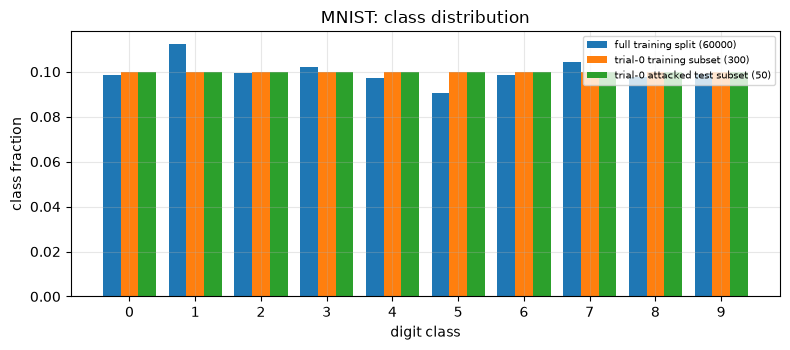

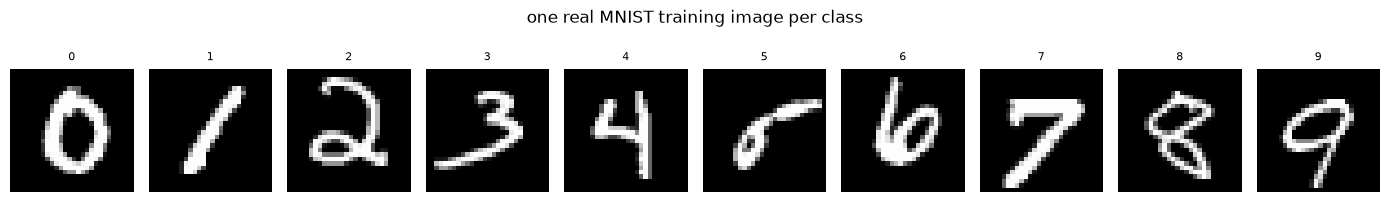

In [5]:
D = DATA; T0 = TRIAL[0]
print(f"MNIST: image array shape {T0['Xtr'].shape[1:]} = {T0['Xtr'].shape[1] * T0['Xtr'].shape[2]} features (pixel grey values, scaled to [0, 1]); "
      f"full data {D['shape_full'][0]} (train) and {D['shape_full'][1]} (test); trial-0 pixels min {T0['Xtr'].min():.2f}, max {T0['Xtr'].max():.2f}, mean {T0['Xtr'].mean():.3f}")
print("feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27")
print("original label values:", sorted(set(D['ypool'].tolist())), "->", CLASS_NAMES)
cnt = pd.DataFrame({"class": CLASS_NAMES, "full train (60000)": D["full_train_counts"], "full test (10000)": D["full_test_counts"],
                    "visualisation pool (2000)": np.bincount(D["ypool"], minlength=10),
                    f"trial-0 training subset ({len(T0['ytr'])})": np.bincount(T0["ytr"], minlength=10), f"trial-0 attacked test subset ({len(T0['yte'])})": np.bincount(T0["yte"], minlength=10)})
display(cnt)

fig, ax = plt.subplots(1, 1, figsize=(8, 3.6)); w = 0.27; xs = np.arange(10)
ax.bar(xs - w, D["full_train_counts"] / D["full_train_counts"].sum(), w, label="full training split (60000)")
ax.bar(xs, np.bincount(T0["ytr"], minlength=10) / len(T0["ytr"]), w, label=f"trial-0 training subset ({N_TRAIN})")
ax.bar(xs + w, np.bincount(T0["yte"], minlength=10) / len(T0["yte"]), w, label=f"trial-0 attacked test subset ({N_TEST})")
ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES); ax.set_xlabel("digit class"); ax.set_ylabel("class fraction"); ax.set_title("MNIST: class distribution"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(14, 1.9))
for c in range(10):
    i = np.flatnonzero(D["ypool"] == c)[0]
    axes[c].imshow(D["Xpool"][i], cmap="gray", vmin=0, vmax=1); axes[c].axis("off"); axes[c].set_title(CLASS_NAMES[c], fontsize=8)
plt.suptitle("one real MNIST training image per class", y=1.05); plt.tight_layout(); plt.show()

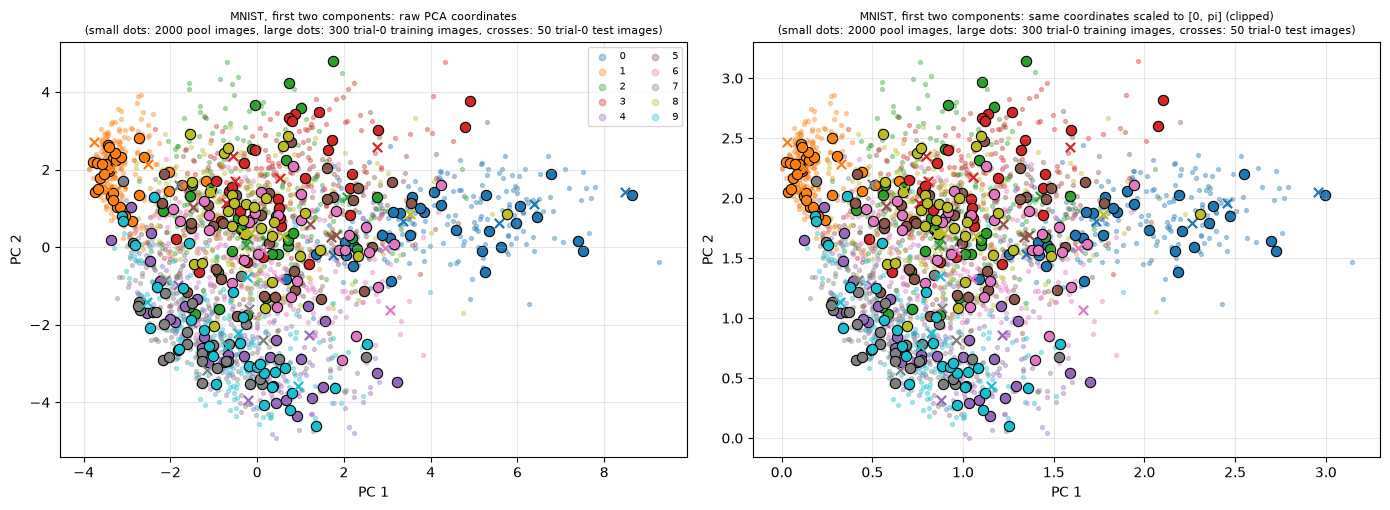

MNIST: variance explained by the two components = 16.7% (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)


In [6]:
# 2-D scatter of real observations coloured by ground-truth label. PCA is fitted on the 2000-image training pool only; trial-0 train / test images are projected.
cmap = plt.get_cmap("tab10")
flat = lambda A: A.reshape(len(A), -1)
pca = PCA(n_components=2, random_state=SEED).fit(flat(D["Xpool"]))
Zp, Ztr, Zte = pca.transform(flat(D["Xpool"])), pca.transform(flat(T0["Xtr"])), pca.transform(flat(T0["Xte"]))
sc = MinMaxScaler((0, np.pi)).fit(Zp)                                  # fitted on the training pool only
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, (A, B, C, ttl) in zip(axes, [(Zp, Ztr, Zte, "raw PCA coordinates"),
                                     (sc.transform(Zp), np.clip(sc.transform(Ztr), 0, np.pi), np.clip(sc.transform(Zte), 0, np.pi), "same coordinates scaled to [0, pi] (clipped)")]):
    for c in range(10):
        m = D["ypool"] == c; ax.scatter(A[m, 0], A[m, 1], s=8, color=cmap(c), alpha=0.35, label=CLASS_NAMES[c])
    for c in range(10):
        m = T0["ytr"] == c; ax.scatter(B[m, 0], B[m, 1], s=55, color=cmap(c), edgecolor="k", linewidth=0.8)
        m = T0["yte"] == c; ax.scatter(C[m, 0], C[m, 1], s=45, marker="x", color=cmap(c), linewidth=1.6)
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(f"MNIST, first two components: {ttl}\n(small dots: 2000 pool images, large dots: {N_TRAIN} trial-0 training images, crosses: {N_TEST} trial-0 test images)", fontsize=8)
axes[0].legend(fontsize=7, ncol=2, markerscale=1.6)
plt.tight_layout(); plt.show()
print(f"MNIST: variance explained by the two components = {pca.explained_variance_ratio_.sum():.1%} (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)")

## 2. The five Ansatz architectures and an exact simulator

Each Ansatz is written as a short list of blocks on 4 qubits (`rot` = `Rot(phi, theta, omega)` with three free angles, `rx`/`ry`/`rz` with one free angle, `zz` = `CNOT - RZ(phi) - CNOT` = `exp(-i phi Z Z / 2)` with one free angle, `cx`):

| key | paper (Section 3.1) | blocks | free angles |
|---|---|---|---|
| `no_ent` | no entangled qubit | 4 x `Rot` | 12 |
| `zz_full` | full qubit entanglement (all-to-all ZZ) | 4 x `Rot`, ZZ on all 6 pairs | 18 |
| `zz_linear` | linear (nearest-neighbour ZZ) | 4 x `Rot`, ZZ on (0,1), (1,2), (2,3) | 15 |
| `zz_star` | star (qubit 0 with all others) | 4 x `Rot`, ZZ on (0,1), (0,2), (0,3) | 15 |
| `random` | random gate selection, a single entangling operation | 4 random rotations + 1 random `CNOT` (`# CHOICE`), new circuit per trial | 4 |

Two representations of the *same* block list are used: a small batched **NumPy statevector simulator** (`run_ops`), fast enough for 196 patches x many images with analytic gradients, and a **PennyLane QNode**
(built in the circuit section further below from the same list) that is drawn and used to cross-check the simulator with an assertion.
`Rot(phi, theta, omega)` follows PennyLane's convention `RZ(omega) RY(theta) RZ(phi)`; since the angles are random, this is the same family of unitaries as the paper's `Rz(a) Ry(b) Rz(c)`.

In [7]:
# ------------------------------------------------------------ Ansatz architectures (paper Section 3.1), 4 qubits ------------------------------------------------------------
# Blocks: ("rot", q) 3 angles | ("rx"|"ry"|"rz", q) 1 angle | ("zz", a, b) = CNOT(a,b) RZ(phi on b) CNOT(a,b), 1 angle | ("cx", c, t)
def arch_ops(name, rng=None):
    rots = [("rot", q) for q in range(4)]
    if name == "no_ent":    return rots
    if name == "zz_full":   return rots + [("zz", a, b) for a in range(4) for b in range(a + 1, 4)]
    if name == "zz_linear": return rots + [("zz", q, q + 1) for q in range(3)]
    if name == "zz_star":   return rots + [("zz", 0, q) for q in range(1, 4)]
    if name == "random":
        # CHOICE: "random gate selection ... a single entanglement operation": 4 rotations of random type on random qubits and one random CNOT at a random position
        ops = [(str(rng.choice(["rx", "ry", "rz"])), int(rng.integers(4))) for _ in range(4)]
        c, t = rng.choice(4, 2, replace=False); ops.insert(int(rng.integers(len(ops) + 1)), ("cx", int(c), int(t)))
        return ops
    raise ValueError(name)

N_ANGLES = {"rot": 3, "rx": 1, "ry": 1, "rz": 1, "zz": 1, "cx": 0}
def n_params(ops): return sum(N_ANGLES[o[0]] for o in ops)

# ------------------------------------------------------------ batched NumPy statevector simulator ------------------------------------------------------------
# State array (B,2,2,2,2): axis q+1 is qubit q, qubit 0 is the most significant bit of the 16-vector (same convention as PennyLane).
def _rot(g, th):
    c, s = np.cos(th / 2), np.sin(th / 2)
    M = np.zeros((th.shape[0], 2, 2), complex)
    if g == "rx":
        M[:, 0, 0] = c; M[:, 1, 1] = c; M[:, 0, 1] = -1j * s; M[:, 1, 0] = -1j * s
    elif g == "ry":
        M[:, 0, 0] = c; M[:, 1, 1] = c; M[:, 0, 1] = -s; M[:, 1, 0] = s
    else:                                                    # rz
        M[:, 0, 0] = np.exp(-1j * th / 2); M[:, 1, 1] = np.exp(1j * th / 2)
    return M
_X = np.array([[0, 1], [1, 0]], complex)

def _apply1(psi, M, q):
    psi = np.moveaxis(psi, q + 1, 1)
    out = np.moveaxis(np.tensordot(M, psi, axes=([1], [1])), 0, 1) if M.ndim == 2 else np.einsum("bij,bj...->bi...", M, psi)
    return np.moveaxis(out, 1, q + 1)

def _cnot(psi, c, t):
    psi = psi.copy(); sl = [slice(None)] * 5; sl[c + 1] = 1
    sub = psi[tuple(sl)]; tq = t if t < c else t - 1
    sub = np.moveaxis(sub, tq + 1, 1)
    o = np.moveaxis(np.tensordot(_X, sub, axes=([1], [1])), 0, 1)
    psi[tuple(sl)] = np.moveaxis(o, 1, tq + 1)
    return psi

def run_ops(ops, theta, psi0):
    # theta: (B, n_params), psi0: (B,2,2,2,2)
    psi = psi0.astype(complex); p = 0
    for op in ops:
        g = op[0]
        if g == "rot":                                                         # qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
            for gg in ("rz", "ry", "rz"): psi = _apply1(psi, _rot(gg, theta[:, p]), op[1]); p += 1
        elif g in ("rx", "ry", "rz"): psi = _apply1(psi, _rot(g, theta[:, p]), op[1]); p += 1
        elif g == "zz": psi = _cnot(psi, op[1], op[2]); psi = _apply1(psi, _rot("rz", theta[:, p]), op[2]); p += 1; psi = _cnot(psi, op[1], op[2])
        elif g == "cx": psi = _cnot(psi, op[1], op[2])
    return psi

def ansatz_unitary(ops, theta):
    # 16 x 16 unitary of the Ansatz for ONE parameter vector (columns = images of the basis states)
    psi0 = np.zeros((16, 2, 2, 2, 2), complex); psi0.reshape(16, 16)[np.arange(16), np.arange(16)] = 1
    return run_ops(ops, np.tile(theta[None, :], (16, 1)), psi0).reshape(16, 16).T

print("architecture | free angles | blocks")
for a in ARCHS:
    o = arch_ops(a, np.random.default_rng(SEED)); print(f"{a:>10} | {n_params(o):>11} | {o}")

architecture | free angles | blocks
    no_ent |          12 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3)]
   zz_full |          18 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3), ('zz', 0, 1), ('zz', 0, 2), ('zz', 0, 3), ('zz', 1, 2), ('zz', 1, 3), ('zz', 2, 3)]
 zz_linear |          15 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3), ('zz', 0, 1), ('zz', 1, 2), ('zz', 2, 3)]
   zz_star |          15 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3), ('zz', 0, 1), ('zz', 0, 2), ('zz', 0, 3)]
    random |           4 | [('rx', 3), ('ry', 1), ('ry', 3), ('rx', 2), ('cx', 0, 3)]


## 3. The quanvolution layer, the classical models, the dense head and the attacks

**Quanvolution.** For a patch `x = (x0, x1, x2, x3)` (the four pixels of a 2 x 2 block) qubit *q* starts in `RY(s x_q)|0> = cos(s x_q / 2)|0> + sin(s x_q / 2)|1>` (`s = ENC_SCALE`), the Ansatz `U(theta)` is applied, and channel *k*
is `<Z_k>`. Because the encoding is a product state and `U` is a fixed 16 x 16 unitary, the layer is a fixed smooth map `[0,1]^4 -> [-1, 1]^4`, and its Jacobian can be written down exactly,
`d<Z_k>/dx_j = 2 s Re(<phi| Z_k U |dpsi/dalpha_j>)`. The gradient needed by FGSM / PGD / MIM is therefore the **exact analytic gradient** (no sampling, no finite differences); it is verified against central finite differences below.

**Classical models.**
* `CNN` - the paper's classical model: `Conv2D(4 filters, 2 x 2, stride 2, relu)` with a **frozen** (non-trainable) Glorot-uniform kernel, followed by the dense layer.
* `CNN_train` - the same convolution but trainable (an extra control; the paper does not train the convolution).
* `PERIODIC` - the **no-quantum control**: a frozen classical 2 x 2 / stride-2 convolution with 4 filters followed by `cos(w . patch + b)` (`w ~ N(0,1)`, `b ~ U[0, 2 pi)`). Like `<Z>` it is bounded in [-1, 1] and periodic in the pixel values, but nothing is quantum.
  If the QuNN advantage under the paper's attacks also appears here, it is a property of bounded periodic feature maps, not of quantum circuits.

**Dense head.** `Flatten (784) -> Dense(10, softmax)`, trained with Adam (learning rate 0.001, batch 4, 30 epochs, sparse categorical cross-entropy), written in NumPy so no TensorFlow is needed.

**Attacks (L-infinity, white-box, pixels clipped to [0, 1]).** FGSM `x' = clip(x + eps sign(grad))`, PGD `x_{t+1} = clip(Proj_eps(x_t + alpha sign(grad)))`,
MIM `g_{t+1} = mu g_t + grad / |grad|_1`, `x_{t+1} = clip(Proj_eps(x_t + alpha sign(g_{t+1})))` (paper Section 3.2). The attacker sees the whole model, including the quantum layer.
**Added here:** an *adaptive* attack = PGD on the **margin loss** `max_{j != y} z_j - z_y` (immune to softmax saturation), started from random points in the epsilon-ball, repeated with restarts,
counting an image as broken if it is misclassified at *any* iterate of *any* restart; and a *random-noise* attack (random signs of size epsilon, worst case over a few draws) as a floor for a gradient-free adversary.

In [8]:
# ------------------------------------------------------------ data layout: 2x2 patches, stride 2 ------------------------------------------------------------
def to_patches(X):          # (N,28,28) -> (N,196,4); pixel order (0,0),(0,1),(1,0),(1,1) = qubits 0..3
    n = X.shape[0]; return X.reshape(n, 14, 2, 14, 2).transpose(0, 1, 3, 2, 4).reshape(n, 196, 4)
def from_patches(P):
    n = P.shape[0]; return P.reshape(n, 14, 14, 2, 2).transpose(0, 1, 3, 2, 4).reshape(n, 28, 28)

IDX = np.arange(16)
ZMAT = np.stack([1.0 - 2.0 * ((IDX >> (3 - k)) & 1) for k in range(4)], 1)       # (16,4): diagonal of Z_k for the 16 basis states

def _kron4(v0, v1, v2, v3):
    n = v0.shape[0]
    a = (v0[:, :, None] * v1[:, None, :]).reshape(n, 4); b = (v2[:, :, None] * v3[:, None, :]).reshape(n, 4)
    return (a[:, :, None] * b[:, None, :]).reshape(n, 16)

def product_state(P, deriv=None):
    # RY(a_q)|0> on every qubit (qubit 0 = most significant); deriv=j returns d/d(angle_j) of it. P holds the ANGLES a_q
    c, s = np.cos(P / 2), np.sin(P / 2)
    v = [np.stack([c[:, q], s[:, q]], 1) for q in range(4)]
    if deriv is not None: v[deriv] = 0.5 * np.stack([-s[:, deriv], c[:, deriv]], 1)
    return _kron4(*v)

class Quanv:
    '''Frozen quanvolution layer: <Z_k> of U(theta) RY(enc x)|0000>, 2x2 patches, stride 2, 4 channels -> 784 features.'''
    trainable = False
    def __init__(self, ops, theta, enc):
        self.ops, self.theta, self.enc = ops, theta, enc
        self.U = ansatz_unitary(ops, theta)
        self.RI = np.concatenate([self.U.T.real, self.U.T.imag], 1)          # psi @ RI = [Re, Im] of U psi
    def _amp(self, P):
        A = product_state(self.enc * P) @ self.RI; return A[:, :16], A[:, 16:]
    def forward(self, X, train=False):                                       # processed in chunks of 50 images to keep memory small
        return np.concatenate([self._forward(X[i:i + 50]) for i in range(0, len(X), 50)])
    def backward(self, X, g):                                                # g: (N,784) upstream gradient -> gradient w.r.t. the images
        return np.concatenate([self._backward(X[i:i + 50], g[i:i + 50]) for i in range(0, len(X), 50)])
    def _forward(self, X):
        Ar, Ai = self._amp(to_patches(X).reshape(-1, 4))
        return ((Ar ** 2 + Ai ** 2) @ ZMAT).reshape(X.shape[0], 196 * 4)
    def _backward(self, X, g):
        P = to_patches(X).reshape(-1, 4); g = g.reshape(-1, 4)
        Ar, Ai = self._amp(P); w = g @ ZMAT.T; out = np.empty_like(P)
        for j in range(4):
            dA = product_state(self.enc * P, j) @ self.RI
            out[:, j] = 2 * self.enc * np.sum(w * (Ar * dA[:, :16] + Ai * dA[:, 16:]), 1)
        return from_patches(out.reshape(X.shape[0], 196, 4))

def glorot(rng, fan_in, fan_out):
    lim = math.sqrt(6.0 / (fan_in + fan_out)); return rng.uniform(-lim, lim, (fan_in, fan_out))

class ConvFront:
    '''Classical Conv2D(4 filters, 2x2, stride 2, relu), Keras Glorot-uniform kernel (fan_in 4, fan_out 16), zero bias. trainable=False is the paper's frozen CNN.'''
    def __init__(self, rng, trainable):
        lim = math.sqrt(6.0 / (4 + 16)); self.W = rng.uniform(-lim, lim, (4, 4)); self.b = np.zeros(4); self.trainable = trainable
    def params(self): return [self.W, self.b]
    def grads(self): return [self.gW, self.gb]
    def forward(self, X, train=False):
        self.P = to_patches(X); self.z = self.P @ self.W + self.b; return np.maximum(self.z, 0).reshape(X.shape[0], 784)
    def backward(self, X, g):                                                # uses the cache of the last forward call on the same X
        gz = g.reshape(-1, 196, 4) * (self.z > 0)
        if self.trainable: self.gW = np.einsum("npi,npj->ij", self.P, gz); self.gb = gz.sum((0, 1))
        return from_patches(gz @ self.W.T)

class PeriodicFront:
    '''No-quantum control: frozen classical 2x2/stride-2 convolution, 4 filters, cos(w.patch + b): bounded in [-1,1] and periodic like <Z>, but classical.'''
    trainable = False
    def __init__(self, rng):
        self.W = rng.normal(0, 1, (4, 4)); self.b = rng.uniform(0, 2 * np.pi, 4)          # CHOICE: w ~ N(0,1), b ~ U[0, 2 pi)
    def forward(self, X, train=False):
        self.z = to_patches(X) @ self.W + self.b; return np.cos(self.z).reshape(X.shape[0], 784)
    def backward(self, X, g):
        return from_patches((g.reshape(-1, 196, 4) * -np.sin(self.z)) @ self.W.T)

class Dense:
    def __init__(self, rng, n_in, n_out):
        self.W, self.b = glorot(rng, n_in, n_out), np.zeros(n_out)
    def params(self): return [self.W, self.b]
    def grads(self): return [self.gW, self.gb]
    def forward(self, x, train=False):
        self.x = x; return x @ self.W + self.b
    def backward(self, g):
        self.gW = self.x.T @ g; self.gb = g.sum(0); return g @ self.W.T

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

class Model:
    def __init__(self, front, head): self.front, self.head = front, head
    def logits(self, X, train=False):
        h = self.front.forward(X, train)
        for L in self.head: h = L.forward(h, train)
        return h
    def pred(self, X): return self.logits(X).argmax(1)
    def acc(self, X, y): return float((self.pred(X) == y).mean())
    def grad(self, X, y, loss="ce"):
        '''gradient of the per-sample loss w.r.t. the input image (inference mode). loss="ce": cross-entropy; loss="margin": max_{j!=y} z_j - z_y.'''
        z = self.logits(X); ar = np.arange(len(y))
        if loss == "ce":
            p = softmax(z); p[ar, y] -= 1
        else:
            zz = z.copy(); zz[ar, y] = -np.inf; p = np.zeros_like(z); p[ar, zz.argmax(1)] = 1.0; p[ar, y] = -1.0
        for L in reversed(self.head): p = L.backward(p)
        return self.front.backward(X, p)

def train_model(model, X, y, rng, epochs=EPOCHS, bs=BATCH_SIZE, lr=LR):
    # Adam with Keras defaults (beta1 0.9, beta2 0.999, eps 1e-7), batch size 4, sparse categorical cross-entropy (mean over the batch)
    params = [p for L in model.head for p in L.params()] + (model.front.params() if model.front.trainable else [])
    m_ = [np.zeros_like(p) for p in params]; v_ = [np.zeros_like(p) for p in params]; b1, b2, eps = 0.9, 0.999, 1e-7; t = 0
    Y = np.eye(10)[y]; n = len(y)
    F_all = None if model.front.trainable else model.front.forward(X)          # frozen front end (quantum layer / frozen conv): features computed once
    for ep in range(epochs):
        perm = rng.permutation(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            h = model.front.forward(X[idx], True) if model.front.trainable else F_all[idx]
            for L in model.head: h = L.forward(h, True)
            g = (softmax(h) - Y[idx]) / len(idx)
            for L in reversed(model.head): g = L.backward(g)
            if model.front.trainable: model.front.backward(X[idx], g)
            grads = [q for L in model.head for q in L.grads()] + (model.front.grads() if model.front.trainable else [])
            t += 1; a = lr * math.sqrt(1 - b2 ** t) / (1 - b1 ** t)
            for p, gr, mm, vv in zip(params, grads, m_, v_):
                mm *= b1; mm += (1 - b1) * gr; vv *= b2; vv += (1 - b2) * gr ** 2; p -= a * mm / (np.sqrt(vv) + eps)
    return model

# ---------------------------------------------------- the paper's three white-box attacks (Section 3.2) ----------------------------------------------------
def fgsm(m, X, y, eps): return np.clip(X + eps * np.sign(m.grad(X, y)), 0, 1)
def pgd(m, X, y, eps, k):
    alpha = 2.5 * eps / k; xa = X.copy()                                     # CHOICE: step 2.5 eps / k, no random start
    for _ in range(k):
        xa = np.clip(np.clip(xa + alpha * np.sign(m.grad(xa, y)), X - eps, X + eps), 0, 1)
    return xa
def mim(m, X, y, eps, k, mu=MIM_MU):
    alpha = 2.5 * eps / k; xa = X.copy(); gm = np.zeros_like(X)
    for _ in range(k):
        gr = m.grad(xa, y); gm = mu * gm + gr / (np.abs(gr).sum((1, 2), keepdims=True) + 1e-12)       # per-image L1 normalisation
        xa = np.clip(np.clip(xa + alpha * np.sign(gm), X - eps, X + eps), 0, 1)
    return xa

# ---------------------------------------------------- attacks added by this notebook (NOT in the paper) ----------------------------------------------------
def adaptive_attack(m, X, y, eps, k, restarts, rng):
    '''Margin-loss PGD from random starts; returns a boolean array: True = the image is still classified correctly at EVERY iterate of EVERY restart.'''
    robust = np.ones(len(X), bool); alpha = 2.5 * eps / k
    for _ in range(restarts):
        xa = np.clip(X + rng.uniform(-eps, eps, X.shape), 0, 1); robust &= (m.pred(xa) == y)
        for _ in range(k):
            xa = np.clip(np.clip(xa + alpha * np.sign(m.grad(xa, y, "margin")), X - eps, X + eps), 0, 1)
            robust &= (m.pred(xa) == y)
    return robust
def noise_attack(m, X, y, eps, draws, rng):
    '''Gradient-free floor: random +-eps signs on every pixel, worst case over a few draws (True = correct under all draws).'''
    ok = np.ones(len(X), bool)
    for _ in range(draws): ok &= (m.pred(np.clip(X + eps * rng.choice([-1.0, 1.0], X.shape), 0, 1)) == y)
    return ok

# --- sanity check: analytic input gradient of the whole QuNN vs central finite differences ---
_r = np.random.default_rng(SEED)
_Xs, _ys = TRIAL[0]["Xtr"][:3], TRIAL[0]["ytr"][:3]
_PIX = [tuple(int(v) for v in np.unravel_index(k, (28, 28))) for k in np.argsort(-_Xs[1].ravel())[[0, 40, 80, 120]]]      # four ink pixels (away from the ReLU kink at 0)
for _a in ("zz_full", "random"):
    _ops = arch_ops(_a, _r); _q = Quanv(_ops, _r.uniform(0, 2 * np.pi, n_params(_ops)), ENC_SCALE)
    _m = train_model(Model(_q, [Dense(_r, 784, 10)]), TRIAL[0]["Xtr"], TRIAL[0]["ytr"], _r, epochs=2)
    _g = _m.grad(_Xs, _ys); _loss = lambda X: float(-np.log(softmax(_m.logits(X))[np.arange(3), _ys]).sum())
    errs = []
    for (_i, _j) in _PIX:
        e = np.zeros_like(_Xs); e[1, _i, _j] = 1e-6
        errs.append(abs((_loss(_Xs + e) - _loss(_Xs - e)) / 2e-6 - _g[1, _i, _j]))
    print(f"{_a}: max |analytic - finite-difference| input gradient over 4 pixels = {max(errs):.2e}  (gradient scale ~ {np.abs(_g).max():.2e})")
    assert max(errs) < 1e-5
# the same check for the classical models (including the margin-loss gradient used by the adaptive attack)
for _name in ("CNN", "PERIODIC"):
    _f = ConvFront(_r, False) if _name == "CNN" else PeriodicFront(_r)
    _m = Model(_f, [Dense(_r, 784, 10)]); _g = _m.grad(_Xs, _ys, "margin")
    def _marg(X):
        z = _m.logits(X); zz = z.copy(); zz[np.arange(3), _ys] = -np.inf; return float((zz.max(1) - z[np.arange(3), _ys]).sum())
    errs = []
    for (_i, _j) in _PIX:
        e = np.zeros_like(_Xs); e[1, _i, _j] = 1e-6; errs.append(abs((_marg(_Xs + e) - _marg(_Xs - e)) / 2e-6 - _g[1, _i, _j]))
    print(f"{_name}: margin-loss gradient vs finite differences, max error = {max(errs):.2e}"); assert max(errs) < 1e-5

zz_full: max |analytic - finite-difference| input gradient over 4 pixels = 4.00e-10  (gradient scale ~ 1.25e-01)


random: max |analytic - finite-difference| input gradient over 4 pixels = 2.96e-10  (gradient scale ~ 1.00e-01)
CNN: margin-loss gradient vs finite differences, max error = 7.12e-11
PERIODIC: margin-loss gradient vs finite differences, max error = 5.77e-10


## Quantum Circuit Architecture

Every QuNN in this notebook uses one of the circuits drawn below: a layer of `RY(s x_q)` encoding gates (`qml.AngleEmbedding(s * x, rotation="Y")`, one per qubit, angle = `ENC_SCALE` times the pixel value), the Ansatz (parameterised rotations and, for the ZZ architectures,
`CNOT - RZ - CNOT` entanglers), and a Pauli-Z read-out of each qubit (four expectation values = four output channels). The circuit is executed once per 2 x 2 patch (196 times per image). The Ansatz angles are **frozen**
(drawn once per trial from [0, 2 pi) and never trained); the only trainable parameters of a QuNN are those of the dense head (7 850).

The cell after the next one **asserts** that the NumPy simulator used for all the experiments gives the same `<Z_k>` as the PennyLane QNode for these exact circuits (all five architectures, random angles, random patches).
Where the paper omits a detail (the random circuit; the angle distribution; the free ZZ angles) the choice is documented in the table at the top and in `arch_ops`. For the random architecture the drawing shows the circuit of trial 0.
The classical models (`CNN`, `CNN_train`, `PERIODIC`) contain no quantum circuit and are not drawn.

In [9]:
dev = qml.device("default.qubit", wires=4)

def make_qnode(ops, enc):
    '''PennyLane QNode of one quanvolution patch: angle encoding RY(enc x), Ansatz blocks, <Z> on each qubit.'''
    @qml.qnode(dev)
    def circuit(x, theta):
        qml.AngleEmbedding(enc * x, wires=range(4), rotation="Y")
        p = 0
        for op in ops:
            g = op[0]
            if g == "rot": qml.Rot(theta[p], theta[p + 1], theta[p + 2], wires=op[1]); p += 3
            elif g == "rx": qml.RX(theta[p], wires=op[1]); p += 1
            elif g == "ry": qml.RY(theta[p], wires=op[1]); p += 1
            elif g == "rz": qml.RZ(theta[p], wires=op[1]); p += 1
            elif g == "zz": qml.CNOT(wires=[op[1], op[2]]); qml.RZ(theta[p], wires=op[2]); qml.CNOT(wires=[op[1], op[2]]); p += 1
            elif g == "cx": qml.CNOT(wires=[op[1], op[2]])
        return [qml.expval(qml.PauliZ(w)) for w in range(4)]
    return circuit

# the circuits actually trained in trial t (random architecture: a new circuit per trial)
def trial_arch(arch, t):
    r = np.random.default_rng(np.random.SeedSequence([SEED, t, 31337, ARCHS.index(arch)]))
    ops = arch_ops(arch, r); return ops, r.uniform(0, 2 * np.pi, n_params(ops))          # CHOICE: random frozen Ansatz angles, uniform in [0, 2 pi)

# --- sanity check: NumPy simulator == PennyLane QNode, for every architecture (3 random-circuit draws), random angles, random patches, both encoding scales ---
_r = np.random.default_rng(SEED + 7); worst = 0.0
for enc in sorted({ENC_SCALE, np.pi}):
    for arch in ARCHS:
        for t in (range(3) if arch == "random" else [0]):
            ops, th = trial_arch(arch, t); th = _r.uniform(0, 2 * np.pi, n_params(ops)); q = Quanv(ops, th, enc); qn = make_qnode(ops, enc)
            P = _r.uniform(0, 1, (6, 4)); fq = q.forward(from_patches(np.tile(P[:, None, :], (1, 196, 1)))).reshape(6, 196, 4)[:, 0, :]
            for i in range(6):
                worst = max(worst, np.abs(np.array(qn(P[i], th)) - fq[i]).max())
print(f"max |<Z_k>_numpy - <Z_k>_pennylane| over the 5 architectures = {worst:.2e}")
assert worst < 1e-10, "NumPy simulator and PennyLane disagree"
print("OK: the NumPy simulator used below is the same function as the PennyLane circuits drawn below.")

max |<Z_k>_numpy - <Z_k>_pennylane| over the 5 architectures = 7.77e-16
OK: the NumPy simulator used below is the same function as the PennyLane circuits drawn below.


In [10]:
# circuit facts: qubits, depth, parameter counts, gate content (PennyLane specs of the executed QNode, decomposed into RX/RY/RZ/CNOT; the head size is the number of trainable parameters)
HEAD_PARAMS = 784 * 10 + 10
rows = []
for arch in ARCHS:
    ops, th = trial_arch(arch, 0); qn = make_qnode(ops, ENC_SCALE); x0 = np.full(4, 0.5)
    sp = qml.specs(qml.transforms.decompose(qn, gate_set={"RX", "RY", "RZ", "CNOT"}), level="device")(x0, th)          # decomposed into RX/RY/RZ/CNOT (Rot -> RZ RY RZ)
    rows.append({"architecture": arch, "qubits": sp.num_device_wires, "depth (encoding + Ansatz)": sp.resources.depth, "frozen Ansatz angles": n_params(ops),
                 "encoding angles (pixels)": 4, "gates": ", ".join(f"{k}:{v}" for k, v in sorted(sp.resources.gate_types.items())), "measurements": "4 x <Z>"})
circ_table = pd.DataFrame(rows).set_index("architecture"); display(circ_table)
print("Trainable parameters of one QuNN = dense head only (the quantum circuit is a frozen feature extractor, as in the paper):", HEAD_PARAMS,
      "| circuits executed per image:", 196, "(14 x 14 patches), 4 qubits each")

,qubits,depth (encoding + Ansatz),frozen Ansatz angles,encoding angles (pixels),gates,measurements
architecture,,,,,,
no_ent,4,4,12,4,"RY:8, RZ:8",4 x <Z>
zz_full,4,19,18,4,"CNOT:12, RY:8, RZ:14",4 x <Z>
zz_linear,4,13,15,4,"CNOT:6, RY:8, RZ:11",4 x <Z>
zz_star,4,13,15,4,"CNOT:6, RY:8, RZ:11",4 x <Z>
random,4,4,4,4,"CNOT:1, RX:1, RY:5, RZ:2",4 x <Z>


Trainable parameters of one QuNN = dense head only (the quantum circuit is a frozen feature extractor, as in the paper): 7850 | circuits executed per image: 196 (14 x 14 patches), 4 qubits each


Matplotlib is building the font cache; this may take a moment.


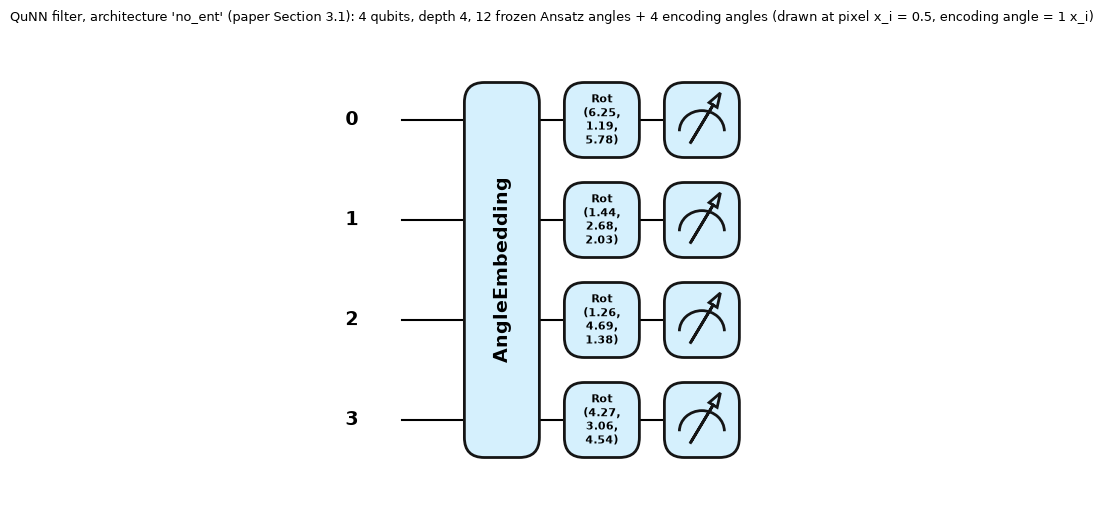

Matplotlib is building the font cache; this may take a moment.


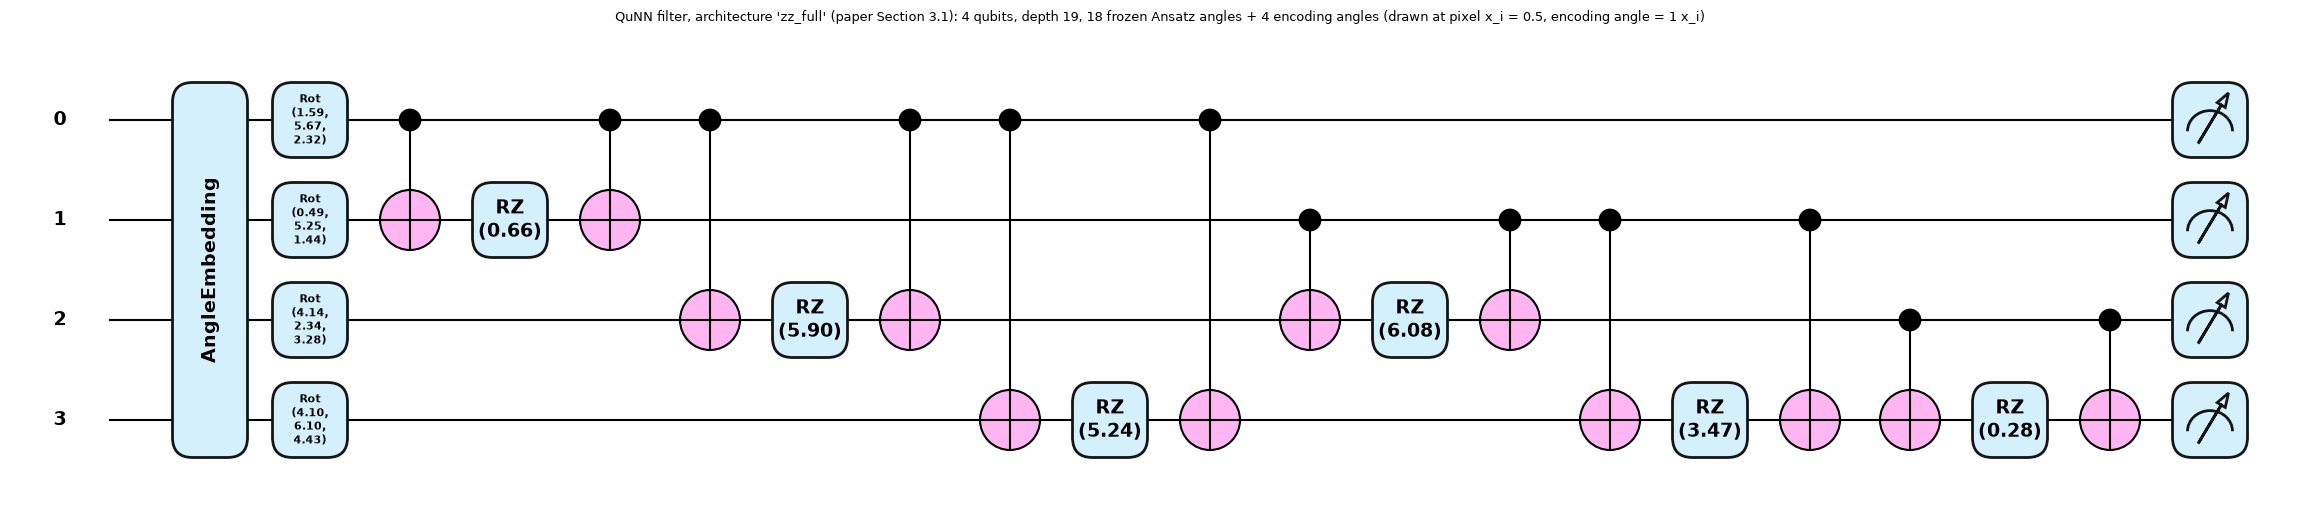

Matplotlib is building the font cache; this may take a moment.


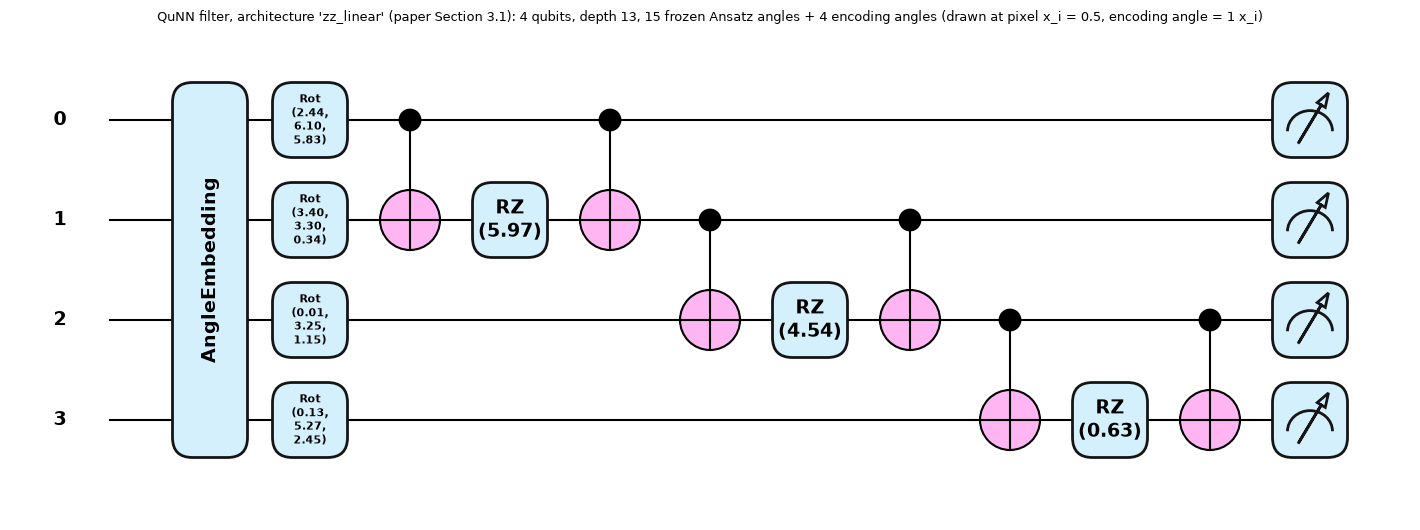

Matplotlib is building the font cache; this may take a moment.


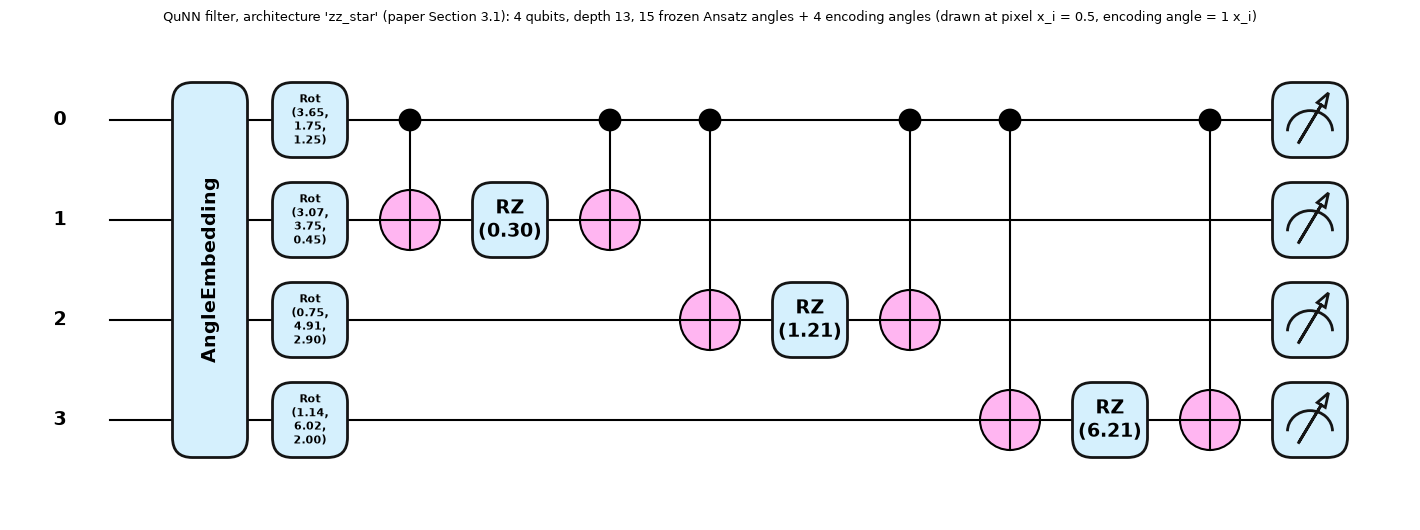

Matplotlib is building the font cache; this may take a moment.


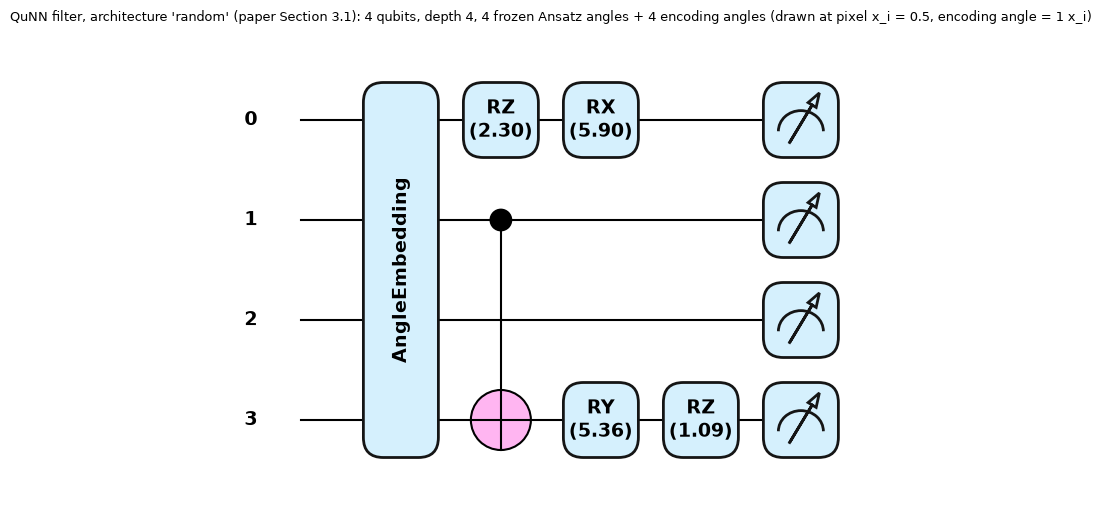

In [11]:
# draw every distinct architecture that is trained or evaluated (the QNode that is actually executed: encoding, Ansatz, read-out)
for arch in ARCHS:
    ops, th = trial_arch(arch, 0); qn = make_qnode(ops, ENC_SCALE)
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(np.full(4, 0.5), th)
    fig.suptitle(f"QuNN filter, architecture '{arch}' (paper Section 3.1): 4 qubits, depth {circ_table.loc[arch, 'depth (encoding + Ansatz)']}, {n_params(ops)} frozen Ansatz angles + 4 encoding angles (drawn at pixel x_i = 0.5, encoding angle = {ENC_SCALE:g} x_i)", fontsize=9, y=1.02)
    display(fig); plt.close(fig)

## 4. Quantum feature space of real data

What does the frozen quantum filter do to real images? For each architecture (and for the classical frozen convolution and the periodic control) the 784 features of 1000 real training-pool images are projected with PCA (fitted on these training images) and coloured by their ground-truth digit class.
The 784-dimensional feature map is what the dense head sees.

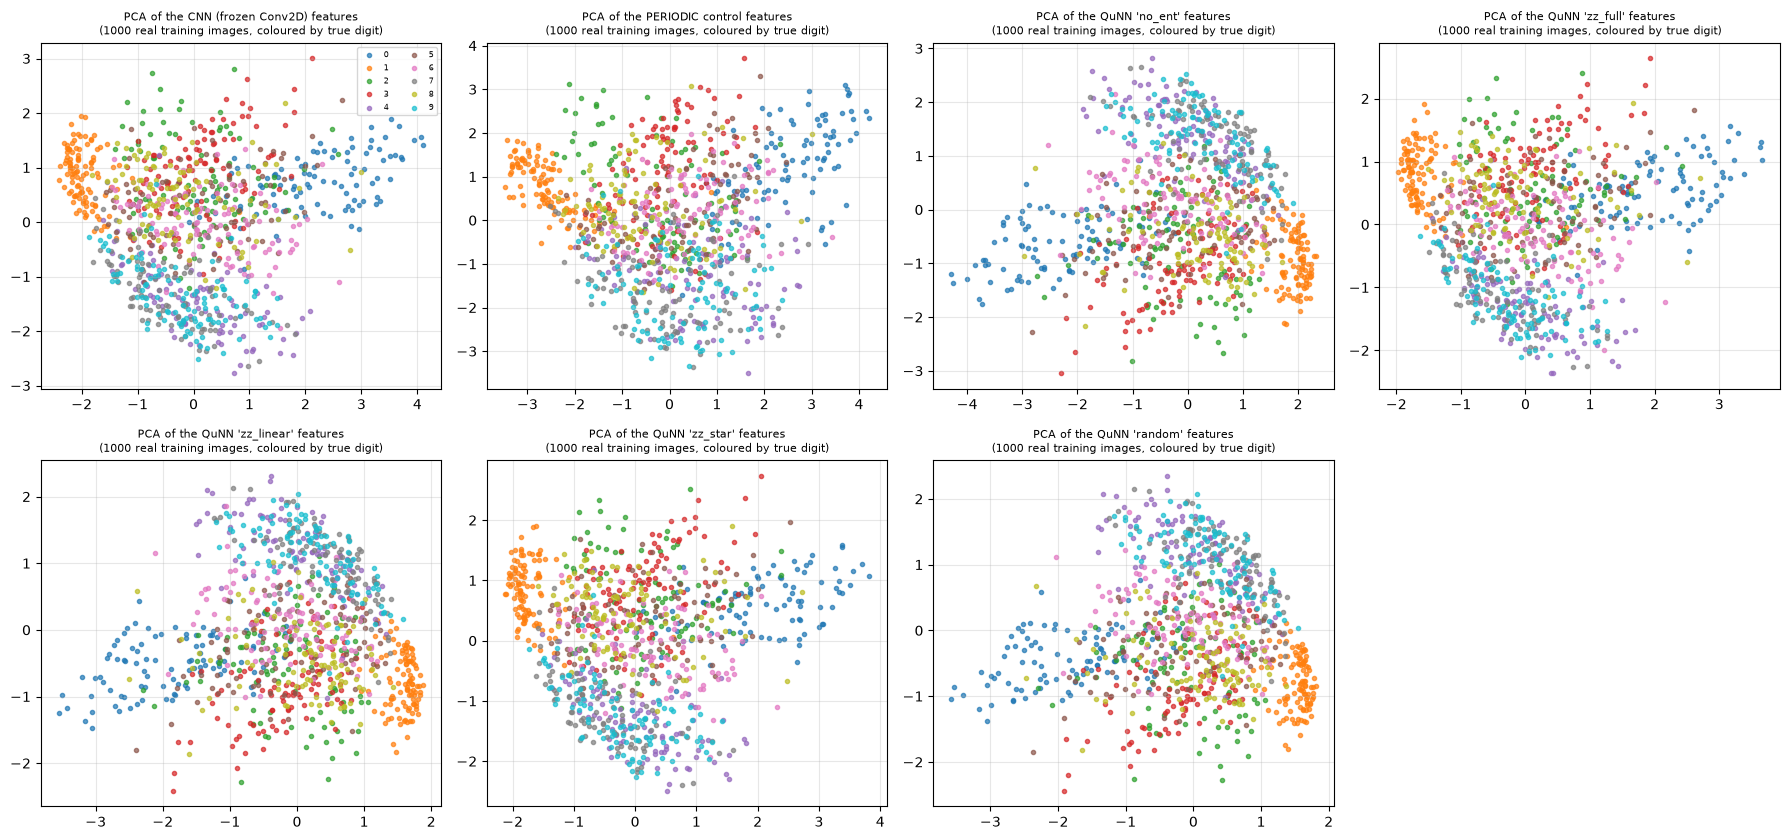

In [12]:
cmap = plt.get_cmap("tab10")
Xp, yp = D["Xpool"][::2], D["ypool"][::2]
fronts = [("CNN (frozen Conv2D)", ConvFront(np.random.default_rng(SEED), False)), ("PERIODIC control", PeriodicFront(np.random.default_rng(SEED)))]
fronts += [(f"QuNN '{a}'", Quanv(*trial_arch(a, 0), ENC_SCALE)) for a in ARCHS]
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, (nm, fr) in zip(axes.ravel(), fronts):
    Z = PCA(n_components=2, random_state=SEED).fit_transform(fr.forward(Xp))
    for c in range(10):
        mk = yp == c; ax.scatter(Z[mk, 0], Z[mk, 1], s=9, color=cmap(c), alpha=0.7, label=CLASS_NAMES[c])
    ax.set_title(f"PCA of the {nm} features\n(1000 real training images, coloured by true digit)", fontsize=8)
axes.ravel()[-1].axis("off"); axes[0, 0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

## 5. Train every model, attack it, repeat over trials

For every trial the loop below

1. takes the `N_TRAIN` training and `N_TEST` test images of the trial (shared by all models),
2. builds the three classical models and the five QuNNs (frozen random filter of each architecture), all with the same dense-head initialisation and the same shuffling stream,
3. trains each model with Adam (batch 4, 30 epochs, learning rate 0.001),
4. records, **image by image** (so that worst cases over attacks can be formed afterwards), whether the model is still correct under **FGSM, PGD and MIM** (the paper's attacks), the **adaptive** attack and the **random-noise** attack for every epsilon of the grid,
5. crafts FGSM examples on every model and records the accuracy of every other model on them (the transfer matrix of Figure 3 d, e).

A progress line is printed per trial.

In [13]:
def make_model(model, t, enc=ENC_SCALE):
    r_front = np.random.default_rng(np.random.SeedSequence([SEED, t, MODELS.index(model), 1]))
    r_init = np.random.default_rng(np.random.SeedSequence([SEED, t, 12345]))              # same head initialisation for every model of a trial
    if model == "CNN": front = ConvFront(r_front, False)
    elif model == "CNN_train": front = ConvFront(r_front, True)
    elif model == "PERIODIC": front = PeriodicFront(r_front)
    else: ops, th = trial_arch(model, t); front = Quanv(ops, th, enc)
    return Model(front, [Dense(r_init, 784, 10)])

ATK_NAMES = ["fgsm", "pgd", "mim", "aa", "rnd"]
def run_one(m, t, model, D, with_aa=True):
    '''Per-image correctness (n_eps x N_TEST, float; NaN = attack not run at this epsilon) under every attack. All attack randomness is seeded.'''
    X, y = D["Xte"], D["yte"]; ne = len(EPS)
    rng = np.random.default_rng(np.random.SeedSequence([SEED, t, MODELS.index(model) if model in MODELS else 99, 555]))
    out = {a: np.full((ne, len(y)), np.nan) for a in ATK_NAMES}
    clean = (m.pred(X) == y); sg = np.sign(m.grad(X, y))
    for i, e in enumerate(EPS):
        if e == 0:
            for a in ATK_NAMES: out[a][i] = clean
            continue
        out["fgsm"][i] = (m.pred(np.clip(X + e * sg, 0, 1)) == y)
        out["pgd"][i] = (m.pred(pgd(m, X, y, e, ATTACK_ITERS)) == y)
        out["mim"][i] = (m.pred(mim(m, X, y, e, ATTACK_ITERS)) == y)
        out["rnd"][i] = noise_attack(m, X, y, e, RND_DRAWS, rng) & clean
        if with_aa and e in AA_EPS:
            ok = np.zeros(len(y), bool); ci = np.flatnonzero(clean)                      # the adaptive attack is run on the clean-correct images only (the others count as not robust)
            ok[ci] = adaptive_attack(m, X[ci], y[ci], e, AA_STEPS, AA_RESTARTS, rng)
            out["aa"][i] = ok
    return out, sg

RES = {mo: {a: [] for a in ATK_NAMES + ["train_acc", "train_time"]} for mo in MODELS}
TRN = {(s, g): [] for s in MODELS for g in MODELS}          # TRN[(source, target)]: per trial, accuracy of the target on FGSM examples crafted on the source (n_eps,)
T_START = time.time()
for t in range(N_TRIALS):
    t_s = time.time(); Dt = TRIAL[t]; M = {}; SG = {}
    for mo in MODELS:
        t0 = time.time(); M[mo] = make_model(mo, t)
        train_model(M[mo], Dt["Xtr"], Dt["ytr"], np.random.default_rng(np.random.SeedSequence([SEED, t, 424242])))      # same shuffling stream for every model
        RES[mo]["train_time"].append(time.time() - t0); RES[mo]["train_acc"].append(M[mo].acc(Dt["Xtr"], Dt["ytr"]))
        o, SG[mo] = run_one(M[mo], t, mo, Dt)
        for a in ATK_NAMES: RES[mo][a].append(o[a])
    for s in MODELS:                                                        # transfer matrix (Fig. 3 d, e): FGSM direction of the source, applied by every target
        for g in MODELS:
            TRN[(s, g)].append(np.array([M[g].acc(np.clip(Dt["Xte"] + e * SG[s], 0, 1), Dt["yte"]) if e > 0 else M[g].acc(Dt["Xte"], Dt["yte"]) for e in EPS]))
    print(f"trial {t + 1}/{N_TRIALS} done in {time.time() - t_s:4.0f} s (elapsed {(time.time() - T_START) / 60:.1f} min)   clean test acc: "
          + ", ".join(f"{k} {RES[k]['fgsm'][-1][0].mean():.2f}" for k in MODELS))
for mo in MODELS:
    for a in ATK_NAMES: RES[mo][a] = np.stack(RES[mo][a])               # (trials, n_eps, N_TEST)
for k in TRN: TRN[k] = np.stack(TRN[k])                                 # (trials, n_eps)
print(f"total {(time.time() - T_START) / 60:.1f} min")

trial 1/2 done in  739 s (elapsed 12.3 min)   clean test acc: CNN 0.80, CNN_train 0.82, PERIODIC 0.86, no_ent 0.86, zz_full 0.66, zz_linear 0.62, zz_star 0.78, random 0.60


trial 2/2 done in  720 s (elapsed 24.3 min)   clean test acc: CNN 0.80, CNN_train 0.86, PERIODIC 0.80, no_ent 0.78, zz_full 0.80, zz_linear 0.74, zz_star 0.80, random 0.80
total 24.3 min


In [14]:
# clean accuracy (eps = 0) and training accuracy, mean +- std over trials
LABEL = {"CNN": "CNN (paper: frozen Conv2D)", "CNN_train": "CNN, trainable conv (control)", "PERIODIC": "PERIODIC frozen classical (no-quantum control)",
         "zz_full": "QuNN ZZ full", "no_ent": "QuNN no entanglement", "zz_linear": "QuNN ZZ linear", "zz_star": "QuNN ZZ star", "random": "QuNN random"}
def acc(model, atk): return np.nanmean(RES[model][atk], axis=2)          # (trials, n_eps)
rows = []
for mo in MODELS:
    c = acc(mo, "fgsm")[:, 0]
    rows.append({"model": LABEL[mo], "train acc": f"{np.mean(RES[mo]['train_acc']):.3f}", "clean test acc": f"{c.mean():.3f} +- {c.std():.3f}",
                 "trainable params": 7850 + (20 if mo == "CNN_train" else 0), "train time / model (s)": f"{np.mean(RES[mo]['train_time']):.1f}"})
display(pd.DataFrame(rows).set_index("model"))

,train acc,clean test acc,trainable params,train time / model (s)
model,,,,
CNN (paper: frozen Conv2D),0.968,0.800 +- 0.000,7850,6.9
"CNN, trainable conv (control)",1.000,0.840 +- 0.020,7870,19.9
PERIODIC frozen classical (no-quantum control),1.000,0.830 +- 0.030,7850,9.5
QuNN no entanglement,0.957,0.820 +- 0.040,7850,9.0
QuNN ZZ full,0.915,0.730 +- 0.070,7850,8.2
QuNN ZZ linear,0.807,0.680 +- 0.060,7850,6.6
QuNN ZZ star,0.952,0.790 +- 0.010,7850,6.2
QuNN random,0.810,0.700 +- 0.100,7850,9.8


In [15]:
# classical baselines on identical inputs (clean accuracy only): RandomForest and RBF-SVC on the raw pixels and on the 784 QuNN (ZZ full) features, same train / test images of every trial
acc_b = {k: [] for k in ("RF raw pixels", "SVC-rbf raw pixels", "RF QuNN zz_full features", "SVC-rbf QuNN zz_full features")}
for t in range(N_TRIALS):
    Dt = TRIAL[t]; F = make_model("zz_full", t).front
    for nm, (A, B) in {"raw pixels": (Dt["Xtr"].reshape(N_TRAIN, -1), Dt["Xte"].reshape(N_TEST, -1)), "QuNN zz_full features": (F.forward(Dt["Xtr"]), F.forward(Dt["Xte"]))}.items():
        acc_b[f"RF {nm}"].append(RandomForestClassifier(n_estimators=200, random_state=SEED).fit(A, Dt["ytr"]).score(B, Dt["yte"]))
        acc_b[f"SVC-rbf {nm}"].append(SVC(kernel="rbf", C=1.0, gamma="scale").fit(A, Dt["ytr"]).score(B, Dt["yte"]))
display(pd.DataFrame([{k: f"{np.mean(v):.3f} +- {np.std(v):.3f}" for k, v in acc_b.items()}], index=["MNIST"]))
print(f"(for reference, the dense heads trained as in the paper reach the clean accuracies in the table above; with only {N_TRAIN} training images all of these classifiers are far from the 98 % obtainable with the full 60000 images)")

,RF raw pixels,SVC-rbf raw pixels,RF QuNN zz_full features,SVC-rbf QuNN zz_full features
MNIST,0.870 +- 0.050,0.860 +- 0.020,0.860 +- 0.040,0.790 +- 0.010


(for reference, the dense heads trained as in the paper reach the clean accuracies in the table above; with only 300 training images all of these classifiers are far from the 98 % obtainable with the full 60000 images)


### 5.1 Figures of the paper, redrawn

**Figure 3 a-c analogue**: the paper's classical CNN and the QuNNs under FGSM, PGD and MIM. Accuracy against perturbation strength epsilon on a symmetric-log axis (epsilon = 0 at the origin), mean over trials with standard-deviation error bars.
The ZZ-full QuNN (the paper's best) is drawn in red; the two extra classical controls are drawn in grey/brown.
**Architecture comparison** (the heart of the RobQuNN methodology): the five Ansatzes under the same attacks.

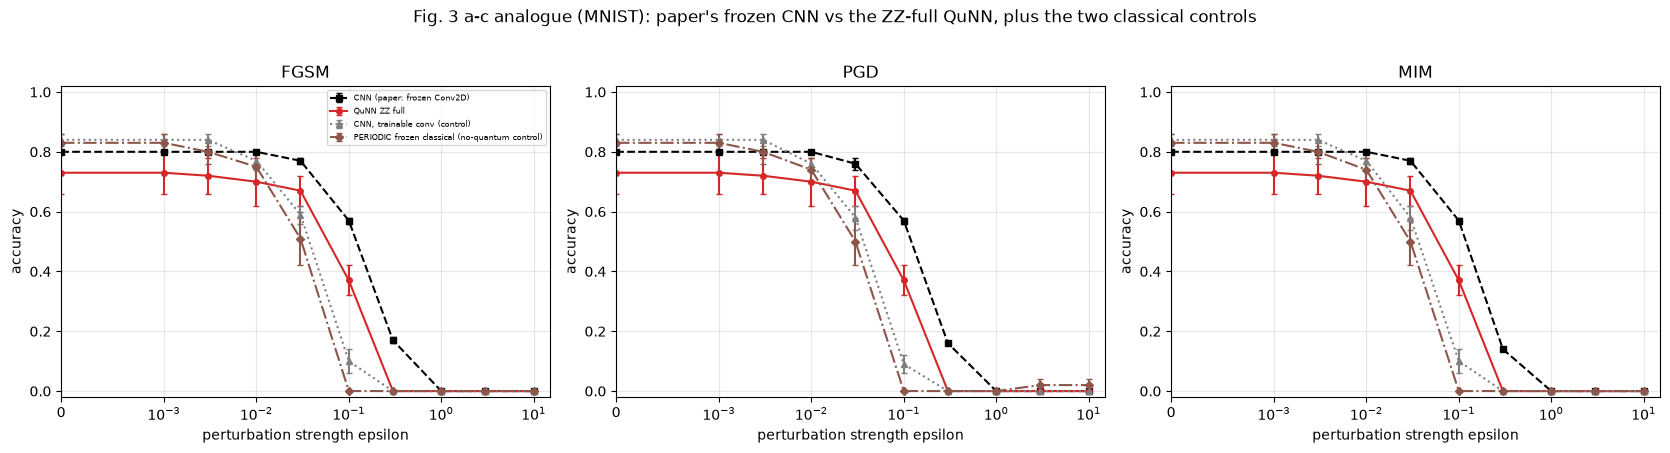

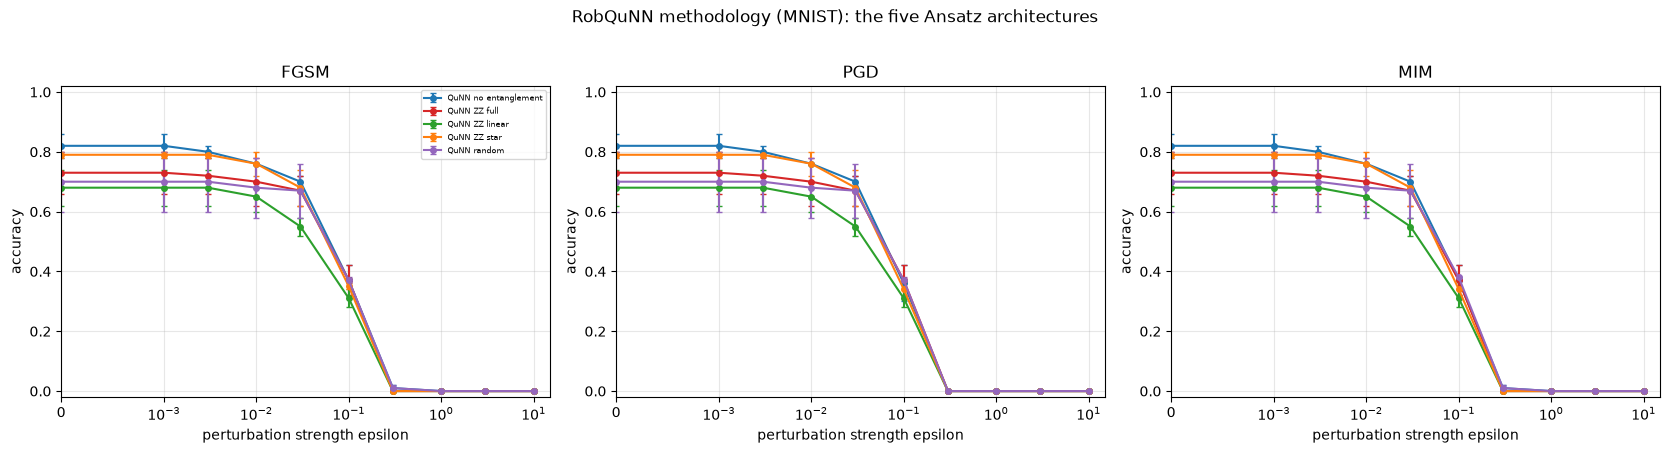

In [16]:
ATKS = [("fgsm", "FGSM"), ("pgd", "PGD"), ("mim", "MIM")]
STYLE = {"CNN": dict(color="k", ls="--", marker="s"), "CNN_train": dict(color="tab:gray", ls=":", marker="^"), "PERIODIC": dict(color="tab:brown", ls="-.", marker="D"),
         "zz_full": dict(color="tab:red", marker="o"), "no_ent": dict(color="tab:blue", marker="o"), "zz_linear": dict(color="tab:green", marker="o"),
         "zz_star": dict(color="tab:orange", marker="o"), "random": dict(color="tab:purple", marker="o")}
def curve(atk, model):
    a = acc(model, atk); return a.mean(0), a.std(0)
def plot_row(title, models, atks=ATKS):
    fig, axes = plt.subplots(1, len(atks), figsize=(5.6 * len(atks), 4.4)); axes = np.atleast_1d(axes)
    for ax, (atk, an) in zip(axes, atks):
        for k in models:
            mu, sd = curve(atk, k); ax.errorbar(EPS, mu, sd, ms=4, capsize=2, label=LABEL[k], **STYLE[k])
        ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlim(0, 15); ax.set_ylim(-0.02, 1.02)
        ax.set_xlabel("perturbation strength epsilon"); ax.set_ylabel("accuracy"); ax.set_title(an)
    axes[0].legend(fontsize=6); fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()
plot_row("Fig. 3 a-c analogue (MNIST): paper's frozen CNN vs the ZZ-full QuNN, plus the two classical controls", ["CNN", "zz_full", "CNN_train", "PERIODIC"])
plot_row("RobQuNN methodology (MNIST): the five Ansatz architectures", ARCHS)

In [17]:
# numerical table behind the curves (mean over trials): accuracy at selected epsilons
SEL = [0.0, 0.01, 0.1, 0.3, 1.0, 10.0]
for atk, an in ATKS:
    T = pd.DataFrame({LABEL[k]: [acc(k, atk).mean(0)[EPS.index(s)] for s in SEL] for k in MODELS}, index=[f"eps={s}" for s in SEL]).T
    print(f"MNIST, {an}: mean accuracy over {N_TRIALS} trials ({N_TEST} test images per trial)"); display(T.round(3))

MNIST, FGSM: mean accuracy over 2 trials (50 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (paper: frozen Conv2D),0.80,0.80,0.57,0.17,0.0,0.0
"CNN, trainable conv (control)",0.84,0.77,0.10,0.00,0.0,0.0
PERIODIC frozen classical (no-quantum control),0.83,0.75,0.00,0.00,0.0,0.0
QuNN no entanglement,0.82,0.76,0.37,0.01,0.0,0.0
QuNN ZZ full,0.73,0.70,0.37,0.00,0.0,0.0
QuNN ZZ linear,0.68,0.65,0.31,0.00,0.0,0.0
QuNN ZZ star,0.79,0.76,0.35,0.00,0.0,0.0
QuNN random,0.70,0.68,0.37,0.01,0.0,0.0


MNIST, PGD: mean accuracy over 2 trials (50 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (paper: frozen Conv2D),0.80,0.80,0.57,0.16,0.0,0.00
"CNN, trainable conv (control)",0.84,0.76,0.09,0.00,0.0,0.00
PERIODIC frozen classical (no-quantum control),0.83,0.74,0.00,0.00,0.0,0.02
QuNN no entanglement,0.82,0.76,0.36,0.00,0.0,0.00
QuNN ZZ full,0.73,0.70,0.37,0.00,0.0,0.00
QuNN ZZ linear,0.68,0.65,0.31,0.00,0.0,0.00
QuNN ZZ star,0.79,0.76,0.34,0.00,0.0,0.00
QuNN random,0.70,0.68,0.37,0.00,0.0,0.00


MNIST, MIM: mean accuracy over 2 trials (50 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (paper: frozen Conv2D),0.80,0.80,0.57,0.14,0.0,0.0
"CNN, trainable conv (control)",0.84,0.77,0.10,0.00,0.0,0.0
PERIODIC frozen classical (no-quantum control),0.83,0.74,0.00,0.00,0.0,0.0
QuNN no entanglement,0.82,0.76,0.37,0.01,0.0,0.0
QuNN ZZ full,0.73,0.70,0.37,0.00,0.0,0.0
QuNN ZZ linear,0.68,0.65,0.31,0.00,0.0,0.0
QuNN ZZ star,0.79,0.76,0.34,0.00,0.0,0.0
QuNN random,0.70,0.68,0.38,0.01,0.0,0.0


### 5.2 Figure 3 d, e: transferability of adversarial examples

FGSM examples are crafted white-box on a *source* model and applied unchanged to a *target* model (same test images, same epsilons). **Figure 3d**: source = the classical CNN, targets = the five QuNNs. **Figure 3e**: sources = the five QuNNs, target = the classical CNN.
The paper concludes that all Ansatzes decline alike in both directions and that the CNN keeps slightly more accuracy against QuNN-crafted examples than the QuNNs against CNN-crafted ones. The `PERIODIC` control is added as a dashed line.

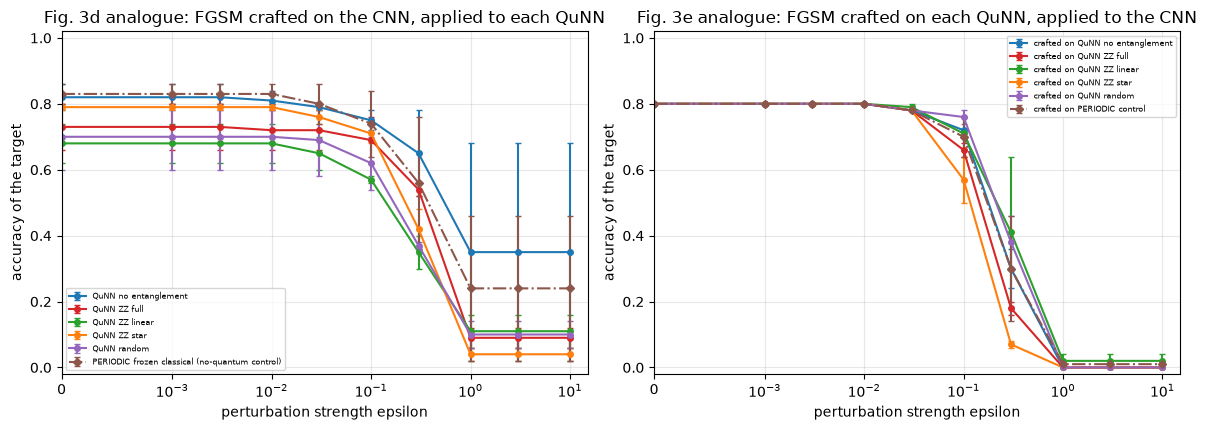

FGSM transfer matrix at epsilon = 0.3 (mean accuracy of the target over trials)


,CNN,CNN_train,PERIODIC,no_ent,zz_full,zz_linear,zz_star,random
source \ target,,,,,,,,
CNN,0.17,0.48,0.56,0.65,0.54,0.35,0.42,0.37
CNN_train,0.01,0.00,0.04,0.03,0.05,0.13,0.05,0.20
PERIODIC,0.30,0.09,0.00,0.45,0.29,0.25,0.18,0.49
no_ent,0.30,0.12,0.30,0.01,0.31,0.26,0.21,0.09
zz_full,0.18,0.06,0.10,0.02,0.00,0.07,0.19,0.18
zz_linear,0.41,0.15,0.20,0.16,0.22,0.00,0.32,0.14
zz_star,0.07,0.07,0.01,0.13,0.18,0.26,0.00,0.21
random,0.38,0.25,0.28,0.17,0.35,0.14,0.31,0.01


In [18]:
def trn(s, g): a = TRN[(s, g)]; return a.mean(0), a.std(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for k in ARCHS:
    mu, sd = trn("CNN", k); axes[0].errorbar(EPS, mu, sd, ms=4, capsize=2, label=LABEL[k], **STYLE[k])
    mu, sd = trn(k, "CNN"); axes[1].errorbar(EPS, mu, sd, ms=4, capsize=2, label=f"crafted on {LABEL[k]}", **STYLE[k])
mu, sd = trn("CNN", "PERIODIC"); axes[0].errorbar(EPS, mu, sd, ms=4, capsize=2, label=LABEL["PERIODIC"], **STYLE["PERIODIC"])
mu, sd = trn("PERIODIC", "CNN"); axes[1].errorbar(EPS, mu, sd, ms=4, capsize=2, label="crafted on PERIODIC control", **STYLE["PERIODIC"])
axes[0].set_title("Fig. 3d analogue: FGSM crafted on the CNN, applied to each QuNN"); axes[1].set_title("Fig. 3e analogue: FGSM crafted on each QuNN, applied to the CNN")
for ax in axes: ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlim(0, 15); ax.set_ylim(-0.02, 1.02); ax.set_xlabel("perturbation strength epsilon"); ax.set_ylabel("accuracy of the target"); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()
# full source x target matrix at eps = 0.3 (rows: source that crafted the FGSM examples, columns: model that classifies them; diagonal = white-box FGSM)
j = EPS.index(0.3)
M3 = pd.DataFrame({g: [TRN[(s, g)].mean(0)[j] for s in MODELS] for g in MODELS}, index=MODELS).round(2); M3.index.name = "source \\ target"
print("FGSM transfer matrix at epsilon = 0.3 (mean accuracy of the target over trials)"); display(M3)

## 6. Stress test: are the robustness claims real, or an artefact of weak attacks?

The sister notebook for AdvQuNN (QC-237) found that the QuNN "recovery" at large epsilon came from one-step FGSM *saturation*: with pixels clipped to [0, 1] every epsilon >= 1 gives the *same* FGSM image, a model whose feature map is bounded and periodic can
classify that one image correctly although the model is not robust at all. The test here is simple and does not rely on any single attack:

* for epsilon >= 1 **every image of the pixel cube [0, 1]^784 is reachable**, so the true robust accuracy is exactly 0 for any model that predicts at least two different classes. Any non-zero accuracy there is an attack failure, not robustness.
* at moderate epsilon the signature of a weak attack is a **large gap between what the paper's three attacks leave standing and what the adaptive attack leaves standing** for the same model. Section 6.1 shows that this is exactly what happens to the paper's frozen CNN.
* more generally, an adversarial example that works at epsilon' <= epsilon also works at epsilon. The **worst-case envelope** `E(eps)` therefore counts an image as robust at epsilon only if it is correct (clean) *and* correct under *every* attack
  (FGSM, PGD, MIM, adaptive, random noise) at *every* epsilon' <= epsilon. It is a valid **upper bound** of the true robust accuracy, monotone in epsilon by construction.

In [19]:
def envelope(model):
    '''(trials, n_eps) worst-case envelope accuracy over all attacks and all epsilon' <= epsilon (NaN = attack not run = no constraint).'''
    out = np.zeros((N_TRIALS, len(EPS)))
    for t in range(N_TRIALS):
        clean = RES[model]["fgsm"][t][0] == 1; run = clean.copy()
        for i, e in enumerate(EPS):
            if i > 0:
                for a in ATK_NAMES: run &= np.nan_to_num(RES[model][a][t][i], nan=1.0) == 1
            out[t, i] = run.mean()
    return out
ENV = {mo: envelope(mo) for mo in MODELS}
def acc_any(model, atk): return ENV[model] if atk == "env" else acc(model, atk)

# --- every model, every attack, in one table at selected epsilons (mean over trials) ---
rows = []
for mo in MODELS:
    for e in (0.03, 0.1, 0.3, 1.0, 10.0):
        i = EPS.index(e)
        rows.append({"model": LABEL[mo], "eps": e, "FGSM": acc(mo, "fgsm").mean(0)[i], "PGD": acc(mo, "pgd").mean(0)[i], "MIM": acc(mo, "mim").mean(0)[i],
                     "adaptive": np.nanmean(acc(mo, "aa")[:, i]) if e in AA_EPS else np.nan, "random noise": acc(mo, "rnd").mean(0)[i], "worst-case envelope": ENV[mo].mean(0)[i]})
pd.set_option("display.max_colwidth", 200, "display.width", 250)
display(pd.DataFrame(rows).set_index(["model", "eps"]).round(3))

FGSM   PGD   MIM  adaptive  random noise  worst-case envelope
model                                          eps                                                                 
CNN (paper: frozen Conv2D)                     0.03   0.77  0.76  0.77      0.68          0.80                 0.68
                                               0.10   0.57  0.57  0.57      0.15          0.77                 0.15
                                               0.30   0.17  0.16  0.14      0.00          0.42                 0.00
                                               1.00   0.00  0.00  0.00      0.00          0.03                 0.00
                                               10.00  0.00  0.00  0.00      0.00          0.01                 0.00
CNN, trainable conv (control)                  0.03   0.59  0.58  0.58      0.57          0.81                 0.57
                                               0.10   0.10  0.09  0.10      0.09          0.65                 0.09
                                               0.30   0.00  0.00  0.00      0.00          0.29                 0.00
                                               1.00   0.00  0.00  0.00      0.00          0.07                 0.00
                                               10.00  0.00  0.00  0.00      0.00          0.05                 0.00
PERIODIC frozen classical (no-quantum control) 0.03   0.51  0.50  0.50      0.47          0.81                 0.47
                                               0.10   0.00  0.00  0.00      0.00          0.73                 0.00
                                               0.30   0.00  0.00  0.00      0.00          0.44                 0.00
                                               1.00   0.00  0.00  0.00      0.00          0.01                 0.00
                                               10.00  0.00  0.02  0.00      0.00          0.01                 0.00
QuNN no entanglement                           0.03   0.70  0.70  0.70      0.67          0.81                 0.67
                                               0.10   0.37  0.36  0.37      0.33          0.74                 0.33
                                               0.30   0.01  0.00  0.01      0.00          0.59                 0.00
                                               1.00   0.00  0.00  0.00      0.00          0.02                 0.00
                                               10.00  0.00  0.00  0.00      0.00          0.01                 0.00
QuNN ZZ full                                   0.03   0.67  0.67  0.67      0.67          0.73                 0.67
                                               0.10   0.37  0.37  0.37      0.35          0.71                 0.35
                                               0.30   0.00  0.00  0.00      0.00          0.58                 0.00
                                               1.00   0.00  0.00  0.00      0.00          0.06                 0.00
                                               10.00  0.00  0.00  0.00      0.00          0.02                 0.00
QuNN ZZ linear                                 0.03   0.55  0.55  0.55      0.53          0.68                 0.53
                                               0.10   0.31  0.31  0.31      0.30          0.63                 0.30
                                               0.30   0.00  0.00  0.00      0.00          0.50                 0.00
                                               1.00   0.00  0.00  0.00      0.00          0.02                 0.00
                                               10.00  0.00  0.00  0.00      0.00          0.00                 0.00
QuNN ZZ star                                   0.03   0.68  0.68  0.68      0.66          0.79                 0.66
                                               0.10   0.35  0.34  0.34      0.31          0.75                 0.31
                                               0.30   0.00  0.00  0.00      0.00          0.61                

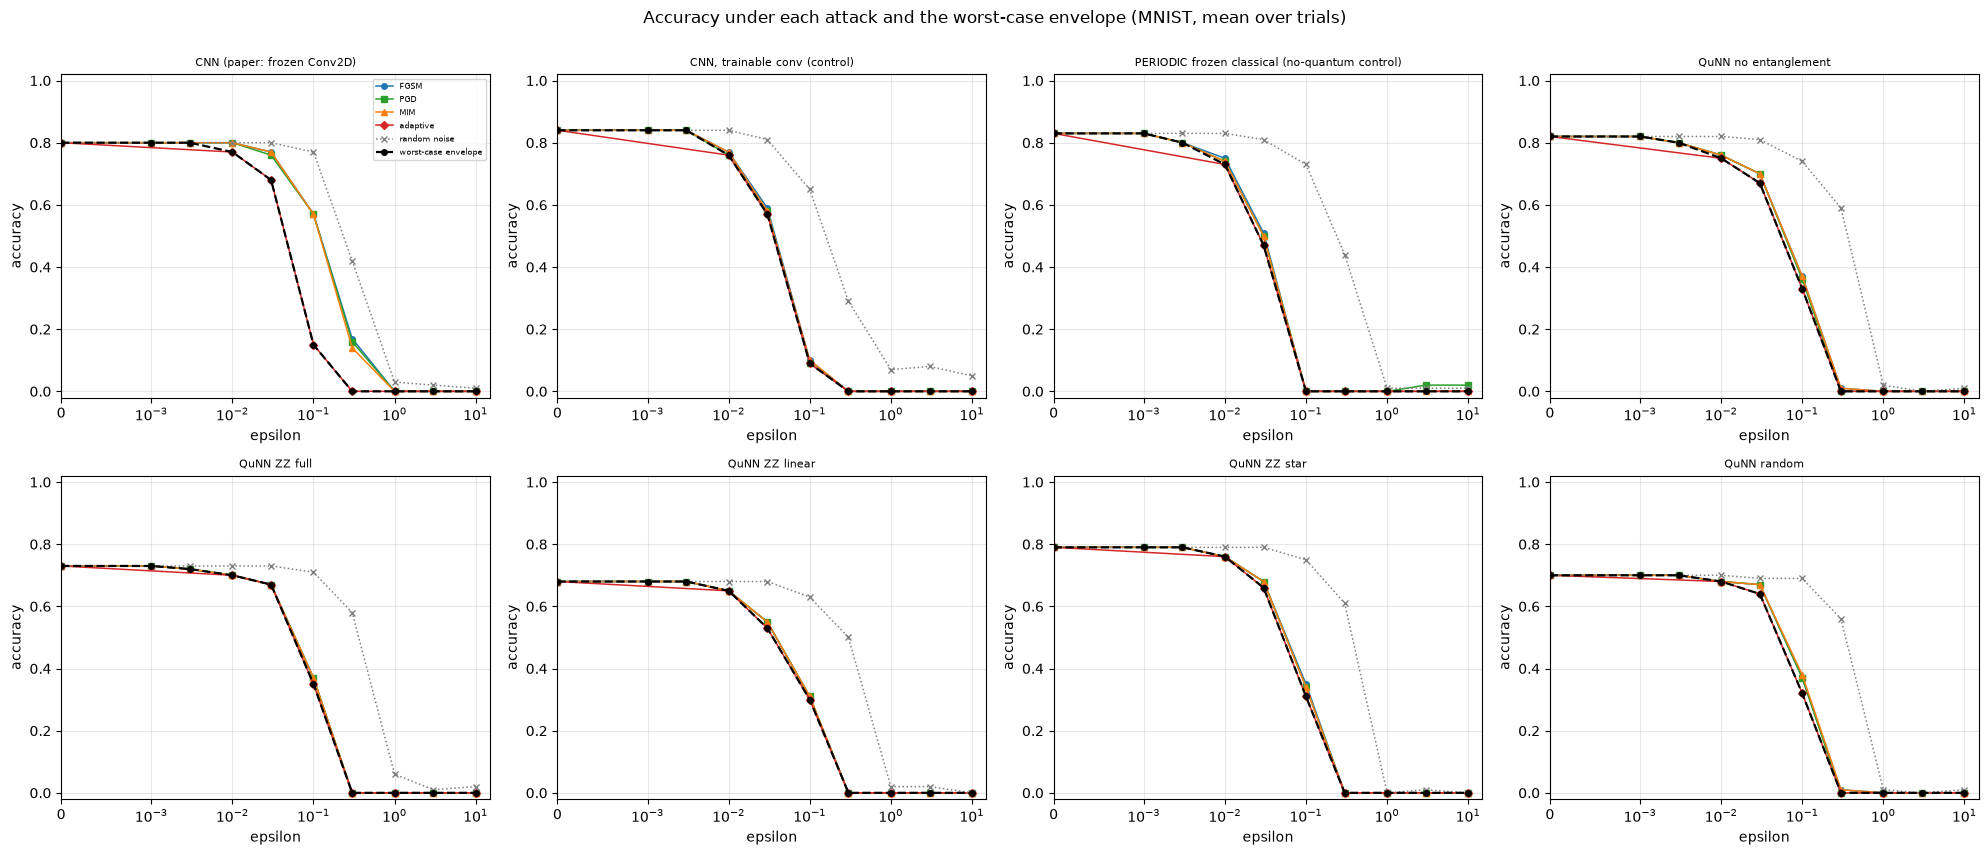

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
PL = [("fgsm", "FGSM", "tab:blue", "o", "-"), ("pgd", "PGD", "tab:green", "s", "-"), ("mim", "MIM", "tab:orange", "^", "-"), ("aa", "adaptive", "tab:red", "D", "-"),
      ("rnd", "random noise", "tab:gray", "x", ":"), ("env", "worst-case envelope", "k", "o", "--")]
for ax, mo in zip(axes.ravel(), MODELS):
    for key, nm, col, mk, ls in PL:
        a = acc_any(mo, key); mu = np.nanmean(a, 0)
        ok = ~np.isnan(mu); ax.plot(np.array(EPS)[ok], mu[ok], color=col, marker=mk, ls=ls, ms=4, lw=1.6 if key == "env" else 1.1, label=nm)
    ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlim(0, 15); ax.set_ylim(-0.02, 1.02); ax.set_title(LABEL[mo], fontsize=8); ax.set_xlabel("epsilon"); ax.set_ylabel("accuracy")
axes[0, 0].legend(fontsize=6); plt.suptitle("Accuracy under each attack and the worst-case envelope (MNIST, mean over trials)", y=1.0); plt.tight_layout(); plt.show()

In [21]:
# gradient-masking diagnostic: at epsilon >= 1 the true robust accuracy is 0, so whatever the paper's attacks leave standing there is an attack failure; at 0.1 and 0.3 the same shows as FGSM >> envelope
rows = []
for mo in MODELS:
    for e in (0.1, 0.3, 1.0, 10.0):
        i = EPS.index(e)
        rows.append({"model": LABEL[mo], "eps": e, "FGSM (paper)": acc(mo, "fgsm").mean(0)[i], "PGD (paper)": acc(mo, "pgd").mean(0)[i], "MIM (paper)": acc(mo, "mim").mean(0)[i],
                     "worst-case envelope": ENV[mo].mean(0)[i], "attack failure = FGSM - envelope": acc(mo, "fgsm").mean(0)[i] - ENV[mo].mean(0)[i]})
DIAG = pd.DataFrame(rows).set_index(["model", "eps"]); display(DIAG.round(3))
# per-trial view of the FGSM accuracy at the saturation level epsilon = 1 (every epsilon >= 1 gives the same adversarial image)
j = EPS.index(1.0); rows = []
for mo in MODELS:
    a = acc(mo, "fgsm")[:, j]; rows.append({"model": mo, **{f"trial {t + 1}": round(float(v), 2) for t, v in enumerate(a)}, "mean": round(float(a.mean()), 3)})
print("FGSM accuracy at epsilon = 1 in every trial:"); display(pd.DataFrame(rows).set_index("model"))

FGSM (paper)  PGD (paper)  MIM (paper)  worst-case envelope  attack failure = FGSM - envelope
model                                          eps                                                                                                
CNN (paper: frozen Conv2D)                     0.1           0.57         0.57         0.57                 0.15                              0.42
                                               0.3           0.17         0.16         0.14                 0.00                              0.17
                                               1.0           0.00         0.00         0.00                 0.00                              0.00
                                               10.0          0.00         0.00         0.00                 0.00                              0.00
CNN, trainable conv (control)                  0.1           0.10         0.09         0.10                 0.09                              0.01
                                               0.3           0.00         0.00         0.00                 0.00                              0.00
                                               1.0           0.00         0.00         0.00                 0.00                              0.00
                                               10.0          0.00         0.00         0.00                 0.00                              0.00
PERIODIC frozen classical (no-quantum control) 0.1           0.00         0.00         0.00                 0.00                              0.00
                                               0.3           0.00         0.00         0.00                 0.00                              0.00
                                               1.0           0.00         0.00         0.00                 0.00                              0.00
                                               10.0          0.00         0.02         0.00                 0.00                              0.00
QuNN no entanglement                           0.1           0.37         0.36         0.37                 0.33                              0.04
                                               0.3           0.01         0.00         0.01                 0.00                              0.01
                                               1.0           0.00         0.00         0.00                 0.00                              0.00
                                               10.0          0.00         0.00         0.00                 0.00                              0.00
QuNN ZZ full                                   0.1           0.37         0.37         0.37                 0.35                              0.02
                                               0.3           0.00         0.00         0.00                 0.00                              0.00
                                               1.0           0.00         0.00         0.00                 0.00                              0.00
                                               10.0          0.00         0.00         0.00                 0.00                              0.00
QuNN ZZ linear                                 0.1           0.31         0.31         0.31                 0.30                              0.01
                                               0.3           0.00         0.00         0.00                 0.00                              0.00
                                               1.0           0.00         0.00         0.00                 0.00                              0.00
                                               10.0          0.00         0.00         0.00                 0.00                              0.00
QuNN ZZ star                                   0.1           0.35         0.34         0.34                 0.31                              0.04
                                               0.3           0.00         0.00      

FGSM accuracy at epsilon = 1 in every trial:


,trial 1,trial 2,mean
model,,,
CNN,0.0,0.0,0.0
CNN_train,0.0,0.0,0.0
PERIODIC,0.0,0.0,0.0
no_ent,0.0,0.0,0.0
zz_full,0.0,0.0,0.0
zz_linear,0.0,0.0,0.0
zz_star,0.0,0.0,0.0
random,0.0,0.0,0.0


### 6.1 Why does the paper's frozen CNN survive the paper's attacks?

The paper's CNN has a **frozen** `Conv2D` with `relu` and zero bias. On MNIST most 2 x 2 patches are exactly zero (black background). For such a patch the pre-activation is exactly `0`, the `relu` derivative there is `0`, so
the input gradient of **every background pixel is exactly zero** and `sign(0) = 0`: FGSM, PGD and MIM, which start from the clean image and use no random start, can never switch on a background pixel. The QuNN has no such dead zone: `d<Z>/dx` at `x = 0` is non-zero.
The cell below measures the fraction of exactly-zero gradient entries per model and repeats PGD with a **random start** (which leaves the kink), on the models of the last trial.

In [22]:
def pgd_rs(m, X, y, eps, k, rng):
    # same PGD as the paper's, but starting from a random point of the epsilon-ball (the only change)
    alpha = 2.5 * eps / k; xa = np.clip(X + rng.uniform(-eps, eps, X.shape), 0, 1)
    for _ in range(k):
        xa = np.clip(np.clip(xa + alpha * np.sign(m.grad(xa, y)), X - eps, X + eps), 0, 1)
    return xa
Dl = TRIAL[N_TRIALS - 1]; rr = np.random.default_rng(SEED + 5); rows = []
for mo in MODELS:                                    # M holds the trained models of the last trial
    g_ = M[mo].grad(Dl["Xte"], Dl["yte"]); bg = Dl["Xte"] == 0
    row = {"model": LABEL[mo], "zero-gradient pixels (all)": float((g_ == 0).mean()), "zero-gradient pixels (black background)": float((g_[bg] == 0).mean())}
    for e in (0.1, 0.3):
        row[f"PGD acc eps={e}"] = M[mo].acc(pgd(M[mo], Dl["Xte"], Dl["yte"], e, ATTACK_ITERS), Dl["yte"])
        row[f"PGD + random start eps={e}"] = M[mo].acc(pgd_rs(M[mo], Dl["Xte"], Dl["yte"], e, ATTACK_ITERS, rr), Dl["yte"])
    rows.append(row)
GM = pd.DataFrame(rows).set_index("model"); display(GM.round(3))
print(f"last trial, {N_TEST} test images: the frozen ReLU CNN has exactly zero gradient on its background pixels, so the paper's attacks cannot touch them; a random start restores the attack.")

,zero-gradient pixels (all),zero-gradient pixels (black background),PGD acc eps=0.1,PGD + random start eps=0.1,PGD acc eps=0.3,PGD + random start eps=0.3
model,,,,,,
CNN (paper: frozen Conv2D),0.735,0.918,0.56,0.18,0.16,0.0
"CNN, trainable conv (control)",0.000,0.000,0.12,0.12,0.00,0.0
PERIODIC frozen classical (no-quantum control),0.000,0.000,0.00,0.00,0.00,0.0
QuNN no entanglement,0.000,0.000,0.30,0.30,0.00,0.0
QuNN ZZ full,0.000,0.000,0.32,0.32,0.00,0.0
QuNN ZZ linear,0.000,0.000,0.28,0.28,0.00,0.0
QuNN ZZ star,0.000,0.000,0.34,0.34,0.00,0.0
QuNN random,0.601,0.750,0.36,0.34,0.00,0.0


last trial, 50 test images: the frozen ReLU CNN has exactly zero gradient on its background pixels, so the paper's attacks cannot touch them; a random start restores the attack.


## 7. Side-by-side comparison with the paper, claim by claim

The paper reports its results as plots and prose, not as tables, so the checks below translate each statement into a rule that can be challenged. The *robustness score* of a model on one panel is its mean accuracy over the non-zero epsilons of the attack, averaged over trials
("low" = 0 < epsilon <= 0.1, "all" = every non-zero epsilon of the grid). **Reproduced** when the rule is satisfied, **not reached** / **exceeded** when a number falls short of / goes beyond the paper's, **cannot be checked** when the paper gives no number.
With `N_TEST` images and a few trials a single accuracy has a standard error of roughly 0.02 to 0.05, so only clear differences are meaningful. The paper's claims are judged on the paper's own attacks (FGSM, PGD, MIM); the stress-test verdicts at the end use the added attacks.

In [23]:
def score(atk, model, region="all"):
    eps = np.array(EPS); a = acc_any(model, atk).mean(0)
    sel = (eps > 0) & ((eps <= 0.1 + 1e-9) if region == "low" else True)
    return float(np.nanmean(a[sel]))

V = []        # (claim, paper, here, verdict, rule)
Q = "zz_full"

# C1: QuNN (ZZ full) more robust than the CNN, low epsilon, all three attacks
d_low = {an: score(atk, Q, "low") - score(atk, "CNN", "low") for atk, an in ATKS}
V.append(("Fig. 3a-c: the QuNN (ZZ full) is more robust than the CNN under FGSM, PGD and MIM, particularly at low epsilon", "QuNN higher in all three panels",
          "low-epsilon score QuNN minus CNN: " + ", ".join(f"{an} {v:+.3f}" for an, v in d_low.items()),
          "reproduced" if all(v > 0.02 for v in d_low.values()) else "not reached", "ZZ-full score exceeds the CNN score by more than 0.02 in all 3 attacks (0 < eps <= 0.1)"))
d_all = {an: score(atk, Q) - score(atk, "CNN") for atk, an in ATKS}
V.append(("Fig. 3a-c: the QuNN's decline is slower, it keeps higher accuracy across the whole range of strengths", "QuNN higher across the range",
          "all-epsilon score QuNN minus CNN: " + ", ".join(f"{an} {v:+.3f}" for an, v in d_all.items()),
          "reproduced" if all(v > 0.02 for v in d_all.values()) else "not reached", "ZZ-full score exceeds the CNN score by more than 0.02 in all 3 attacks (all non-zero epsilon)"))

# C2: "up to 60 % higher robustness"
best, where = -1.0, ""
for atk, an in ATKS:
    for k in ARCHS:
        g = acc(k, atk).mean(0) - acc("CNN", atk).mean(0)
        for i, e in enumerate(EPS):
            if e > 0 and g[i] * 100 > best: best, where = g[i] * 100, f"{LABEL[k]}, {an}, eps={e:g}"
best_low = max(float((acc(k, atk).mean(0) - acc("CNN", atk).mean(0))[[i for i, e in enumerate(EPS) if 0 < e <= 0.1]].max()) * 100 for atk, _ in ATKS for k in ARCHS)
best_env = max(float((ENV[k].mean(0) - ENV["CNN"].mean(0)).max()) for k in ARCHS) * 100
V.append(("Abstract: QuNNs reach 'up to 60 %' higher robustness than the classical CNN on MNIST, particularly at low perturbation", "up to 60 percentage points",
          f"largest accuracy gain over the CNN = {best:.1f} points ({where}); largest gain at eps <= 0.1 = {best_low:.1f} points (for information: under the worst-case envelope the largest gain is {best_env:.1f} points)",
          "reproduced" if abs(best - 60) <= 10 else ("exceeded" if best > 60 else "not reached"), "largest QuNN-minus-CNN accuracy gap (any architecture, attack, epsilon) within 10 points of 60 (reading '% higher robustness' as accuracy points)"))

# C3: architecture ranking
def rank_txt(atk, region="all"): s = {k: score(atk, k, region) for k in ARCHS}; return ">".join(sorted(s, key=s.get, reverse=True)), s
top1, last = 0, 0; txt = []
for atk, an in ATKS:
    o, s = rank_txt(atk); txt.append(f"{an}: {o}"); top1 += max(s, key=s.get) == "zz_full"; last += min(s, key=s.get) == "random"
V.append(("Section 4.2/4.4: ZZ full is the most robust of the five Ansatzes", "ZZ full best", f"ZZ full ranks first in {top1}/3 attacks; rankings (all epsilon): " + "; ".join(txt),
          "reproduced" if top1 >= 2 else "not reached", "ZZ full has the highest all-epsilon score in >= 2 of 3 attacks"))
V.append(("Section 4.2: the random architecture is the least robust", "random worst", f"random ranks last in {last}/3 attacks", "reproduced" if last >= 2 else "not reached", "random has the lowest all-epsilon score in >= 2 of 3 attacks"))
sim = sum(abs(score(atk, "zz_full", "low") - score(atk, "zz_star", "low")) <= 0.05 for atk, _ in ATKS)
V.append(("Section 4.2: at low epsilon ZZ full and ZZ star behave alike (first qubit entangled with all others)", "comparable behaviour", f"|score(ZZ full) - score(ZZ star)| <= 0.05 in {sim}/3 attacks (low epsilon): " +
          ", ".join(f"{an} {score(atk, 'zz_full', 'low'):.3f} vs {score(atk, 'zz_star', 'low'):.3f}" for atk, an in ATKS), "reproduced" if sim >= 2 else "not reached", "score difference <= 0.05 in >= 2 of 3 attacks"))
ent = sum(score(a, "zz_full") > score(a, "no_ent") for a, _ in ATKS)
V.append(("Section 4.4: more connections between the qubits (no entanglement -> ZZ full) give more robust features", "ZZ full above no entanglement", f"ZZ full above no-entanglement in {ent}/3 attacks (all epsilon)", "reproduced" if ent >= 2 else "not reached", ">= 2 of 3 attacks"))

# C4: transferability (Fig. 3 d, e): FGSM, mean over the non-zero epsilons
nz = [i for i, e in enumerate(EPS) if e > 0]
cq = np.array([TRN[("CNN", k)].mean(0)[nz] for k in ARCHS]); qc = np.array([TRN[(k, "CNN")].mean(0)[nz] for k in ARCHS])
sp_cq, sp_qc = float((cq.max(0) - cq.min(0)).mean()), float((qc.max(0) - qc.min(0)).mean())
V.append(("Fig. 3d: CNN -> QuNN, all five Ansatzes decline similarly", "similar declines", f"mean over epsilon of (best - worst Ansatz) accuracy = {sp_cq:.3f}", "reproduced" if sp_cq <= 0.08 else "not reached", "mean spread across the five Ansatzes <= 0.08"))
V.append(("Fig. 3e: QuNN -> CNN, the source Ansatz makes no difference", "consistent pattern", f"mean over epsilon of (best - worst source Ansatz) accuracy = {sp_qc:.3f}", "reproduced" if sp_qc <= 0.08 else "not reached", "mean spread across the five source Ansatzes <= 0.08"))
dd = float(qc.mean() - cq.mean())
V.append(("Section 4.3: the CNN keeps slightly more accuracy against QuNN-crafted examples than the QuNNs against CNN-crafted ones", "CNN 'slightly increased' robustness",
          f"mean accuracy of the CNN on QuNN-crafted FGSM = {qc.mean():.3f}; of the QuNNs on CNN-crafted FGSM = {cq.mean():.3f}; difference {dd:+.3f}",
          "reproduced" if 0.0 < dd <= 0.15 else ("exceeded" if dd > 0.15 else "not reached"), "0 < difference <= 0.15"))
j = EPS.index(0.3); clean_acc = np.mean([acc(k, "fgsm")[:, 0].mean() for k in MODELS])
tr03 = max(float(np.max([TRN[("CNN", k)].mean(0)[j] for k in ARCHS])), float(np.max([TRN[(k, "CNN")].mean(0)[j] for k in ARCHS])))
V.append(("Section 4.3: adversarial examples cross the quantum/classical boundary 'with minimal loss in attack efficacy'", "high transferability", f"at epsilon = 0.3 the best transfer accuracy is {tr03:.3f} against a clean accuracy of {clean_acc:.3f}",
          "reproduced" if tr03 <= 0.5 * clean_acc else "not reached", "transfer accuracy at eps = 0.3 is at most half of the clean accuracy in every pair"))
V.append(("Figure 3: curve values, clean accuracies, training-set size", "plots only", "-", "cannot be checked", "the paper gives no table; clean accuracy and number of images are not stated"))
V.append(("Hardware validation", "none (simulation only)", "-", "cannot be checked", "the paper reports simulator results only"))

VER = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict", "rule"])
display(VER)
print(VER["verdict"].value_counts().to_string())

,claim,paper,this notebook,verdict,rule
0,"Fig. 3a-c: the QuNN (ZZ full) is more robust than the CNN under FGSM, PGD and MIM, particularly at low epsilon",QuNN higher in all three panels,"low-epsilon score QuNN minus CNN: FGSM -0.110, PGD -0.108, MIM -0.110",not reached,ZZ-full score exceeds the CNN score by more than 0.02 in all 3 attacks (0 < eps <= 0.1)
1,"Fig. 3a-c: the QuNN's decline is slower, it keeps higher accuracy across the whole range of strengths",QuNN higher across the range,"all-epsilon score QuNN minus CNN: FGSM -0.080, PGD -0.078, MIM -0.077",not reached,ZZ-full score exceeds the CNN score by more than 0.02 in all 3 attacks (all non-zero epsilon)
2,"Abstract: QuNNs reach 'up to 60 %' higher robustness than the classical CNN on MNIST, particularly at low perturbation",up to 60 percentage points,"largest accuracy gain over the CNN = 2.0 points (QuNN no entanglement, FGSM, eps=0.001); largest gain at eps <= 0.1 = 2.0 points (for information: under the worst-case envelope the largest gain is...",not reached,"largest QuNN-minus-CNN accuracy gap (any architecture, attack, epsilon) within 10 points of 60 (reading '% higher robustness' as accuracy points)"
3,Section 4.2/4.4: ZZ full is the most robust of the five Ansatzes,ZZ full best,ZZ full ranks first in 0/3 attacks; rankings (all epsilon): FGSM: no_ent>zz_star>zz_full>random>zz_linear; PGD: no_ent>zz_star>zz_full>random>zz_linear; MIM: no_ent>zz_star>zz_full>random>zz_linear,not reached,ZZ full has the highest all-epsilon score in >= 2 of 3 attacks
4,Section 4.2: the random architecture is the least robust,random worst,random ranks last in 0/3 attacks,not reached,random has the lowest all-epsilon score in >= 2 of 3 attacks
5,Section 4.2: at low epsilon ZZ full and ZZ star behave alike (first qubit entangled with all others),comparable behaviour,"|score(ZZ full) - score(ZZ star)| <= 0.05 in 3/3 attacks (low epsilon): FGSM 0.638 vs 0.674, PGD 0.638 vs 0.672, MIM 0.638 vs 0.672",reproduced,score difference <= 0.05 in >= 2 of 3 attacks
6,Section 4.4: more connections between the qubits (no entanglement -> ZZ full) give more robust features,ZZ full above no entanglement,ZZ full above no-entanglement in 0/3 attacks (all epsilon),not reached,>= 2 of 3 attacks
7,"Fig. 3d: CNN -> QuNN, all five Ansatzes decline similarly",similar declines,mean over epsilon of (best - worst Ansatz) accuracy = 0.218,not reached,mean spread across the five Ansatzes <= 0.08
8,"Fig. 3e: QuNN -> CNN, the source Ansatz makes no difference",consistent pattern,mean over epsilon of (best - worst source Ansatz) accuracy = 0.067,reproduced,mean spread across the five source Ansatzes <= 0.08
9,Section 4.3: the CNN keeps slightly more accuracy against QuNN-crafted examples than the QuNNs against CNN-crafted ones,CNN 'slightly increased' robustness,mean accuracy of the CNN on QuNN-crafted FGSM = 0.461; of the QuNNs on CNN-crafted FGSM = 0.500; difference -0.039,not reached,0 < difference <= 0.15


verdict
not reached          9
reproduced           2
cannot be checked    2


### 7.1 Stress-test verdicts (added by this notebook, not claims of the paper)

Each line asks whether a headline claim of the paper survives the stronger attacks and the controls. **holds** = the claim is still supported; **fails** = it is not.

In [24]:
S = []
iE = {e: EPS.index(e) for e in EPS}
# S1: gradient masking at epsilon >= 1
fail1 = {k: max(float(np.mean(acc(k, "fgsm").mean(0)[iE[e]] - ENV[k].mean(0)[iE[e]])) for e in (0.1, 0.3, 1.0, 10.0)) for k in MODELS}
S.append(("S1 Gradient masking: largest gap between the paper's FGSM and the worst-case envelope over eps = 0.1, 0.3, 1, 10", "FGSM minus envelope, per model: " + ", ".join(f"{k} {v:+.2f}" for k, v in fail1.items()),
          "masking in: " + (", ".join(k for k, v in fail1.items() if v > 0.05) or "none") ))
# S2: advantage over the CNN under the envelope
adv_env = {k: score("env", k, "low") - score("env", "CNN", "low") for k in ARCHS}
S.append(("S2a QuNN advantage over the CNN under the worst-case envelope (mean over 0 < eps <= 0.1)", "envelope score minus CNN: " + ", ".join(f"{LABEL[k].replace('QuNN ', '')} {v:+.3f}" for k, v in adv_env.items()),
          "holds" if adv_env["zz_full"] > 0.02 else "fails"))
adv01 = {k: ENV[k].mean(0)[iE[0.1]] - ENV["CNN"].mean(0)[iE[0.1]] for k in ARCHS}
S.append(("S2b QuNN advantage over the CNN under the worst-case envelope at eps = 0.1", "envelope accuracy minus CNN: " + ", ".join(f"{LABEL[k].replace('QuNN ', '')} {v:+.3f}" for k, v in adv01.items()) + f" (CNN envelope {ENV['CNN'].mean(0)[iE[0.1]]:.3f})",
          "holds" if adv01["zz_full"] > 0.05 else "fails"))
adv_aa = {k: float(np.nanmean(acc(k, "aa")[:, [iE[e] for e in AA_EPS if e <= 0.1]])) for k in MODELS}
S.append(("S3 Adaptive attack alone, low epsilon (accuracy)", ", ".join(f"{k} {v:.3f}" for k, v in adv_aa.items()), "holds" if adv_aa["zz_full"] - adv_aa["CNN"] > 0.02 else "fails"))
# S4: no-quantum control
gp = {an: score(atk, Q, "low") - score(atk, "PERIODIC", "low") for atk, an in ATKS}
S.append(("S4 No-quantum control (PERIODIC) under the paper's attacks, low epsilon: QuNN ZZ full minus control", ", ".join(f"{an} {v:+.3f}" for an, v in gp.items()),
          "QuNN beats the classical periodic control" if all(v > 0.02 for v in gp.values()) else "the classical periodic control does as well or better"))
ge = score("env", Q, "low") - score("env", "PERIODIC", "low")
S.append(("S5 No-quantum control under the worst-case envelope, low epsilon: QuNN ZZ full minus control", f"{ge:+.3f}", "QuNN beats the classical periodic control" if ge > 0.02 else "the classical periodic control does as well or better"))
# S6: is the paper's frozen CNN a straw man?
ct = score("env", "CNN_train", "low") - score("env", "CNN", "low")
S.append(("S6 Trainable CNN vs the paper's frozen CNN under the envelope, low epsilon", f"trainable minus frozen = {ct:+.3f}", "the frozen CNN is the weaker baseline" if ct > 0.02 else "the frozen CNN is not a straw man"))
# S7: random-noise floor
rn = {k: score("rnd", k, "low") for k in MODELS}; aa_ = {k: float(np.nanmean(acc(k, "aa")[:, [iE[e] for e in AA_EPS if e <= 0.1]])) for k in MODELS}
S.append(("S7 Sanity: random-sign noise is far weaker than the adaptive attack (accuracy, low epsilon)", "random noise / adaptive: " + ", ".join(f"{k} {rn[k]:.2f}/{aa_[k]:.2f}" for k in MODELS),
          "holds" if all(rn[k] > aa_[k] + 0.05 for k in MODELS) else "fails"))
S.append(("S9 Zero-gradient pixels of the paper's frozen CNN vs the QuNN (section 6.1, last trial)", f"CNN {GM.iloc[0, 1]:.2f} of background pixels have exactly zero gradient; QuNN ZZ full {GM.loc[LABEL['zz_full']].iloc[1]:.2f}",
          "CNN gradient dead on the background" if GM.iloc[0, 1] > 0.5 and GM.loc[LABEL['zz_full']].iloc[1] < 0.1 else "no dead zone"))
# S8: best architecture under the envelope
o_env = sorted(ARCHS, key=lambda k: score("env", k), reverse=True)
S.append(("S8 Architecture ranking under the worst-case envelope (all epsilon)", " > ".join(f"{k} ({score('env', k):.3f})" for k in o_env), "ZZ full best" if o_env[0] == "zz_full" else f"best is {o_env[0]}"))
STRESS = pd.DataFrame(S, columns=["test", "measured", "outcome"]); display(STRESS)

,test,measured,outcome
0,"S1 Gradient masking: largest gap between the paper's FGSM and the worst-case envelope over eps = 0.1, 0.3, 1, 10","FGSM minus envelope, per model: CNN +0.42, CNN_train +0.01, PERIODIC +0.00, no_ent +0.04, zz_full +0.02, zz_linear +0.01, zz_star +0.04, random +0.05",masking in: CNN
1,S2a QuNN advantage over the CNN under the worst-case envelope (mean over 0 < eps <= 0.1),"envelope score minus CNN: no entanglement +0.034, ZZ full -0.006, ZZ linear -0.072, ZZ star +0.022, random -0.032",fails
2,S2b QuNN advantage over the CNN under the worst-case envelope at eps = 0.1,"envelope accuracy minus CNN: no entanglement +0.180, ZZ full +0.200, ZZ linear +0.150, ZZ star +0.160, random +0.170 (CNN envelope 0.150)",holds
3,"S3 Adaptive attack alone, low epsilon (accuracy)","CNN 0.533, CNN_train 0.473, PERIODIC 0.400, no_ent 0.583, zz_full 0.573, zz_linear 0.493, zz_star 0.577, random 0.547",holds
4,"S4 No-quantum control (PERIODIC) under the paper's attacks, low epsilon: QuNN ZZ full minus control","FGSM +0.060, PGD +0.064, MIM +0.064",QuNN beats the classical periodic control
5,"S5 No-quantum control under the worst-case envelope, low epsilon: QuNN ZZ full minus control",+0.068,QuNN beats the classical periodic control
6,"S6 Trainable CNN vs the paper's frozen CNN under the envelope, low epsilon",trainable minus frozen = -0.020,the frozen CNN is not a straw man
7,"S7 Sanity: random-sign noise is far weaker than the adaptive attack (accuracy, low epsilon)","random noise / adaptive: CNN 0.79/0.53, CNN_train 0.80/0.47, PERIODIC 0.81/0.40, no_ent 0.80/0.58, zz_full 0.73/0.57, zz_linear 0.67/0.49, zz_star 0.78/0.58, random 0.70/0.55",holds
8,"S9 Zero-gradient pixels of the paper's frozen CNN vs the QuNN (section 6.1, last trial)",CNN 0.92 of background pixels have exactly zero gradient; QuNN ZZ full 0.00,CNN gradient dead on the background
9,S8 Architecture ranking under the worst-case envelope (all epsilon),no_ent (0.374) > zz_star (0.368) > zz_full (0.352) > random (0.338) > zz_linear (0.316),best is no_ent


### 7.2 Ablation: the encoding angle

The paper draws `Ry(x)` but the sister paper (QC-237) used `Ry(pi x)`. With `pi x` the feature map covers half a period more of its sinusoid and is far more non-monotone in the pixels, which is exactly what makes one-step attacks fail at saturation. The cell below repeats the comparison
`CNN` / `PERIODIC` / the ZZ-full and ZZ-linear QuNN with the *other* encoding scale (the one not used above) on the first trials, with FGSM, PGD, MIM, the adaptive attack and the envelope.

In [25]:
ABL = {}
if RUN_PI_ABLATION:
    enc2 = np.pi if ENC_SCALE != np.pi else 1.0; n_ab = 2 if FAST_MODE else 3; ab_models = ["CNN", "PERIODIC", "zz_full", "zz_linear"]
    t_ab = time.time()
    for mo in ab_models:
        lst = {a: [] for a in ATK_NAMES}
        for t in range(n_ab):
            Dt = TRIAL[t]; m = make_model(mo, t, enc2)
            train_model(m, Dt["Xtr"], Dt["ytr"], np.random.default_rng(np.random.SeedSequence([SEED, t, 424242])))
            o, _ = run_one(m, t, mo, Dt)
            for a in ATK_NAMES: lst[a].append(o[a])
        ABL[mo] = {a: np.stack(v) for a, v in lst.items()}
    def abl_env(mo):
        res = []
        for t in range(n_ab):
            run = ABL[mo]["fgsm"][t][0] == 1; row = [run.mean()]
            for i in range(1, len(EPS)):
                for a in ATK_NAMES: run = run & (np.nan_to_num(ABL[mo][a][t][i], nan=1.0) == 1)
                row.append(run.mean())
            res.append(row)
        return np.array(res)
    rows = []
    for mo in ab_models:
        env_ = abl_env(mo).mean(0)
        for e in (0.03, 0.1, 0.3, 1.0):
            i = EPS.index(e); rows.append({"model": LABEL[mo], "eps": e, f"encoding angle = {enc2:.3g} x pixel: FGSM": np.nanmean(ABL[mo]["fgsm"][:, i]), "PGD": np.nanmean(ABL[mo]["pgd"][:, i]),
                                          "adaptive": np.nanmean(ABL[mo]["aa"][:, i]) if e in AA_EPS else np.nan, "envelope": env_[i]})
    display(pd.DataFrame(rows).set_index(["model", "eps"]).round(3))
    print(f"ablation with encoding angle = {enc2:.3g} x pixel on {n_ab} trials took {(time.time() - t_ab) / 60:.1f} min (the main results above use {ENC_SCALE:g} x pixel)")

encoding angle = 3.14 x pixel: FGSM   PGD  adaptive  envelope
model                                          eps                                                                
CNN (paper: frozen Conv2D)                     0.03                                 0.77  0.76      0.68      0.68
                                               0.10                                 0.57  0.57      0.15      0.15
                                               0.30                                 0.17  0.16      0.00      0.00
                                               1.00                                 0.00  0.00      0.00      0.00
PERIODIC frozen classical (no-quantum control) 0.03                                 0.51  0.50      0.47      0.47
                                               0.10                                 0.00  0.00      0.00      0.00
                                               0.30                                 0.00  0.00      0.00      0.00
                                               1.00                                 0.00  0.00      0.00      0.00
QuNN ZZ full                                   0.03                                 0.63  0.62      0.62      0.62
                                               0.10                                 0.22  0.18      0.17      0.17
                                               0.30                                 0.00  0.00      0.00      0.00
                                               1.00                                 0.00  0.00      0.00      0.00
QuNN ZZ linear                                 0.03                                 0.69  0.69      0.68      0.68
                                               0.10                                 0.32  0.32      0.30      0.30
                                               0.30                                 0.00  0.00      0.00      0.00
                                               1.00                                 0.45  0.00      0.00      0.00

ablation with encoding angle = 3.14 x pixel on 2 trials took 5.4 min (the main results above use 1 x pixel)


## 8. Reading the paper critically

*The numbers quoted here come from the stored run (`FAST_MODE = True`: 2 trials, 300 training images and 50 attacked test images per trial, PGD/MIM with 5 steps, adaptive attack with 1 restart x 10 steps). With 100 attacked images in total a single accuracy has a standard error of about 0.03 to 0.05, so differences below roughly 0.05 are not significant. The full budget documented in the configuration cell was not executed (several hours on a shared CPU). The paper gives no table, so all comparisons are with prose statements and the shape of Figure 3.*

**What the re-run does not support (judged on the paper's own attacks).**
* **"QuNNs are more robust than the CNN, up to 60 % at low perturbation" is not reproduced.** Under FGSM, PGD and MIM the paper's frozen CNN keeps 0.57 accuracy at epsilon = 0.1 while every QuNN keeps 0.31 to 0.37 (clean accuracies 0.80 vs 0.68 to 0.82); at epsilon = 0.3 the CNN has 0.17 and all QuNNs about 0.00. The largest accuracy gain of any QuNN over the CNN is 2 points, not 60. All eight curves are at 0 for epsilon >= 1.
* **The Ansatz ranking is not reproduced.** The paper finds ZZ full best and the random circuit worst. Here the order is the same under all three attacks, no entanglement > ZZ star > ZZ full > random > ZZ linear (all-epsilon scores; under the worst-case envelope 0.374 / 0.368 / 0.352 / 0.338 / 0.316). The spread is about the same size as the noise and follows the clean accuracy of each circuit (0.82, 0.79, 0.73, 0.70, 0.68), so we see no evidence that entanglement capability, as such, controls robustness. The one statement that is reproduced is that ZZ full and ZZ star behave alike at low epsilon (they differ by at most 0.04).
* **The transfer picture only half holds.** Examples crafted on the QuNNs hurt the CNN, and the source Ansatz hardly matters (spread 0.07, reproduced). But examples crafted on the CNN are weak against the QuNNs (accuracy of the QuNNs at epsilon = 0.3 between 0.35 and 0.65, against 0.07 to 0.41 for QuNN-crafted examples on the CNN), the five target Ansatzes do not decline alike (spread 0.22), and the CNN is not "slightly more robust" in the reverse direction (difference -0.04). The paper's conclusion that the vulnerabilities are "fundamental to the data" is therefore not what we measure for CNN -> QuNN.

**Why: the paper's CNN baseline is protected by gradient masking, not by robustness (sections 6 and 6.1).** The paper's CNN has a frozen `Conv2D(relu)` with zero bias. On MNIST most 2 x 2 patches are exactly zero; for them the pre-activation is exactly 0 and the ReLU derivative is 0, so **92 % of the gradient entries on black background pixels are exactly zero** (73 % of all entries) and FGSM, PGD and MIM, which start at the clean image, never touch those pixels. The same PGD with a random start brings the CNN from 0.56 to 0.18 accuracy at epsilon = 0.1. The adaptive attack (margin loss, random restarts, success at any iterate) does the same: at epsilon = 0.1 the CNN keeps 0.15, the five QuNNs 0.30 to 0.35. So the *ordering* of the paper's headline comparison flips once the attack is adequate: under the worst-case envelope every QuNN beats the CNN by 0.15 to 0.20 at epsilon = 0.1 (stress test S2b), although averaged over all epsilon <= 0.1 the difference is within the noise (S2a: -0.07 to +0.03). The QuNN curves, in contrast, are almost not masked at all (FGSM minus envelope at most 0.05). A trainable CNN (S6) is no more robust than the frozen one under the envelope, so the frozen CNN is not a straw man, only a badly attacked one.

**The no-quantum control.** A frozen classical convolution with the same bounded periodic output (`PERIODIC`, `cos(w.patch + b)`) is much *less* robust than the QuNN (0.00 vs 0.37 at epsilon = 0.1; S4, S5 +0.06 to +0.07 on average), so boundedness and periodicity alone do not give the QuNN its modest advantage; whether it is "quantum" or just a smooth near-linear map with small slope (with `Ry(x)`, x in [0, 1], every channel is a sinusoid over less than one radian) cannot be decided from this experiment, and the control is one particular classical filter, not an exhaustive one.

**Encoding angle.** The paper draws `Ry(x)`; the sister paper used `Ry(pi x)`. With `pi x` the one-step-attack failure re-appears (ablation 7.2: ZZ linear keeps 0.45 accuracy under FGSM at epsilon = 1, where the true robust accuracy is 0, and 0.00 under the adaptive attack). With `x` there is no saturation recovery at epsilon >= 1 (section 6), so the QC-237 artefact is encoding-dependent.

**Why numbers can differ from the paper.** The paper does not state the number of training or test images, the epsilon grid, the PGD/MIM step size and iteration count, the MIM decay, the random circuit, the frozen-angle distribution, the CNN initialiser or the clean accuracies; the code is not public. We use 300 training images (clean accuracy 0.68 to 0.84), which is probably far fewer than the authors used. The Cleverhans PGD default (no random start) is the one we mimic; if the authors' CNN had a non-zero bias or non-zero background, the dead-gradient effect would be absent and the CNN curve would fall earlier, which would move our result toward theirs. We cannot tell.

**What the notebook adds.** Exact analytic gradients checked against finite differences (also for the margin loss), a NumPy simulator asserted equal to the PennyLane circuits (7.8e-16), a trainable CNN and a no-quantum control, an adaptive attack, a random-noise floor, a worst-case envelope, the transfer matrix, the dead-gradient diagnostic and the encoding-angle ablation. Rerun with `FAST_MODE = False` (or larger `N_TEST`) before drawing conclusions about the architecture ranking.

## Exercises

1. **More images, more trials.** The paper does not state the training-set size. Raise `N_TRAIN` to 1000, `N_TEST` to 300 and `N_TRIALS` to 10 and re-run the architecture comparison: which of the paper's rankings survive once the clean accuracy is above 90 %?
2. **Train the quantum layer.** The paper freezes the quanvolution filter. Add the derivative with respect to the circuit angles (parameter-shift rule, or PennyLane autodiff on `make_qnode`) and train them as well. Does the ZZ-full advantage appear, grow or vanish?
3. **A stronger adaptive attack.** Increase `AA_STEPS` to 100 and `AA_RESTARTS` to 10, add a gradient-free attack (for example a random-search or Square-style attack), and recompute the worst-case envelope. How far does the QuNN curve move?
4. **Other encodings.** Set `ENC_SCALE = np.pi` (as in QC-237) or `2 * np.pi` and compare section 6: how does a larger angle range change the gradient-masking diagnostic?
5. **A real entanglement measure.** The methodology speaks of entanglement capability and expressibility (Sim et al. 2019). Compute the Meyer-Wallach entanglement of the five circuits for random angles and correlate it with the robustness score of each architecture. Is entanglement the quantity that matters, or just the number of free angles?